# EDA and Visualization: NYC Taxi Demand (Manhattan + Queens)

Data: `features.csv` (one row per zone per hour, 8 Sep 2025 - 28 Feb 2026). Charts go to `EDA_doc/figures/`, tables to `EDA_doc/tables/`.

Sections: 1. Zone segmentation (#59) · 2. Demand over time (#60) · 3. Weather (#61) · 4. Feature relationships (#62)

## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

In [2]:
# Dataset files (in the dataset/ folder next to the git folder)
DATA_DIR = "../../../dataset/archive"
FEATURES_FILE = DATA_DIR + "/features.csv"
ZONES_FILE = DATA_DIR + "/NYC-taxi-demand-Manhattan-Queens/kaggle_upload/taxi_zones_manhattan_queens.csv"

# Where charts and tables are saved
FIG_DIR = "../EDA_doc/figures"
TABLE_DIR = "../EDA_doc/tables"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)


def save_fig(name):
    # Save the current chart as a PNG and show it
    plt.tight_layout()
    plt.savefig(FIG_DIR + "/" + name + ".png", dpi=120, bbox_inches="tight")
    plt.show()

### Load the data and join zone names

In [3]:
df = pd.read_csv(FEATURES_FILE, parse_dates=["pickup_hour"])
zones = pd.read_csv(ZONES_FILE)

print("Rows:", len(df))
print("Zones:", df["PULocationID"].nunique())
print("Period:", df["pickup_hour"].min(), "to", df["pickup_hour"].max())
print("Total trips:", df["trip_count"].sum())
df.head()

Rows: 576288
Zones: 138
Period: 2025-09-08 00:00:00 to 2026-02-28 23:00:00
Total trips: 21728117


,PULocationID,pickup_hour,trip_count,apparent_temperature,rain,snowfall,precipitation_probability,hour,day_of_week,month,is_weekend,is_holiday,trip_count_lag_1h,trip_count_lag_24h,trip_count_lag_168h,trip_count_roll_3h,trip_count_roll_24h
0,2,2025-09-08 00:00:00,0,13.8,0.0,0.0,0,0,0,9,False,False,0,0,0,0.0,0.0
1,2,2025-09-08 01:00:00,0,13.5,0.0,0.0,0,1,0,9,False,False,0,0,0,0.0,0.0
2,2,2025-09-08 02:00:00,0,13.5,0.0,0.0,0,2,0,9,False,False,0,0,0,0.0,0.0
3,2,2025-09-08 03:00:00,0,12.7,0.0,0.0,0,3,0,9,False,False,0,0,0,0.0,0.0
4,2,2025-09-08 04:00:00,0,12.3,0.0,0.0,0,4,0,9,False,False,0,0,0,0.0,0.0


In [4]:
# Rename the lookup columns so they match the feature table
zones = zones.rename(columns={
    "LocationID": "PULocationID",
    "Borough": "borough",
    "Zone": "zone_name",
})

# Some zone names repeat (e.g. the three island zones), so add the ID to the label
zones["zone_label"] = zones["zone_name"] + " (" + zones["PULocationID"].astype(str) + ")"

df = df.merge(zones, on="PULocationID", how="left")
zones.head()

,PULocationID,borough,zone_name,service_zone,latitude,longitude,zone_label
0,2,Queens,Jamaica Bay,Boro Zone,40.61675,-73.83130,Jamaica Bay (2)
1,4,Manhattan,Alphabet City,Yellow Zone,40.72375,-73.97697,Alphabet City (4)
2,7,Queens,Astoria,Boro Zone,40.76149,-73.91969,Astoria (7)
3,8,Queens,Astoria Park,Boro Zone,40.77856,-73.92309,Astoria Park (8)
4,9,Queens,Auburndale,Boro Zone,40.75103,-73.78795,Auburndale (9)


### Helper columns (in memory only)

In [5]:
df["date"] = df["pickup_hour"].dt.normalize()


def get_time_band(hour):
    if hour <= 4:
        return "Late night"
    elif hour <= 6:
        return "Early morning"
    elif hour <= 9:
        return "AM rush"
    elif hour <= 15:
        return "Midday"
    elif hour <= 19:
        return "PM rush"
    else:
        return "Evening"


df["time_band"] = df["hour"].apply(get_time_band)

# Day type: Holiday first, then Weekend, otherwise Weekday
df["day_type"] = "Weekday"
df.loc[df["is_weekend"] == True, "day_type"] = "Weekend"
df.loc[df["is_holiday"] == True, "day_type"] = "Holiday"

# The daylight saving hour has about double the normal trips (two clock hours in one)
df["is_dst_hour"] = df["pickup_hour"] == pd.Timestamp("2025-11-02 01:00:00")

df["is_zero"] = df["trip_count"] == 0

DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
TIME_BANDS = ["Late night", "Early morning", "AM rush", "Midday", "PM rush", "Evening"]
BOROUGH_COLORS = {"Manhattan": "tab:blue", "Queens": "tab:orange"}

df[["pickup_hour", "zone_label", "borough", "trip_count", "time_band", "day_type"]].head()

,pickup_hour,zone_label,borough,trip_count,time_band,day_type
0,2025-09-08 00:00:00,Jamaica Bay (2),Queens,0,Late night,Weekday
1,2025-09-08 01:00:00,Jamaica Bay (2),Queens,0,Late night,Weekday
2,2025-09-08 02:00:00,Jamaica Bay (2),Queens,0,Late night,Weekday
3,2025-09-08 03:00:00,Jamaica Bay (2),Queens,0,Late night,Weekday
4,2025-09-08 04:00:00,Jamaica Bay (2),Queens,0,Late night,Weekday


### Zone summary table

In [6]:
zone_stats = df.groupby("PULocationID").agg(
    total_trips=("trip_count", "sum"),
    avg_per_hour=("trip_count", "mean"),
    zero_share=("is_zero", "mean"),
).reset_index()

zone_stats = zone_stats.merge(zones, on="PULocationID")
zone_stats = zone_stats.sort_values("total_trips", ascending=False).reset_index(drop=True)
zone_stats.head(10)

,PULocationID,total_trips,avg_per_hour,zero_share,borough,zone_name,service_zone,latitude,longitude,zone_label
0,237,1015744,243.233716,0.002155,Manhattan,Upper East Side South,Yellow Zone,40.76862,-73.96563,Upper East Side South (237)
1,161,921353,220.630508,0.000479,Manhattan,Midtown Center,Yellow Zone,40.75803,-73.97770,Midtown Center (161)
2,236,919941,220.292385,0.003831,Manhattan,Upper East Side North,Yellow Zone,40.78044,-73.95701,Upper East Side North (236)
3,132,844604,202.251916,0.003592,Queens,JFK Airport,Airports,40.64699,-73.78653,JFK Airport (132)
4,186,690164,165.269157,0.000479,Manhattan,Penn Station/Madison Sq West,Yellow Zone,40.74850,-73.99244,Penn Station/Madison Sq West (186)
5,162,683449,163.661159,0.000479,Manhattan,Midtown East,Yellow Zone,40.75669,-73.97236,Midtown East (162)
6,142,664996,159.242337,0.002395,Manhattan,Lincoln Square East,Yellow Zone,40.77363,-73.98153,Lincoln Square East (142)
7,230,648767,155.356082,0.001676,Manhattan,Times Sq/Theatre District,Yellow Zone,40.75982,-73.98420,Times Sq/Theatre District (230)
8,234,596884,142.931992,0.001437,Manhattan,Union Sq,Yellow Zone,40.74034,-73.99046,Union Sq (234)
9,79,590795,141.473898,0.000479,Manhattan,East Village,Yellow Zone,40.72762,-73.98594,East Village (79)


---
# 1. Zone demand segmentation and predictability (#59)

## C1. Zone ranking

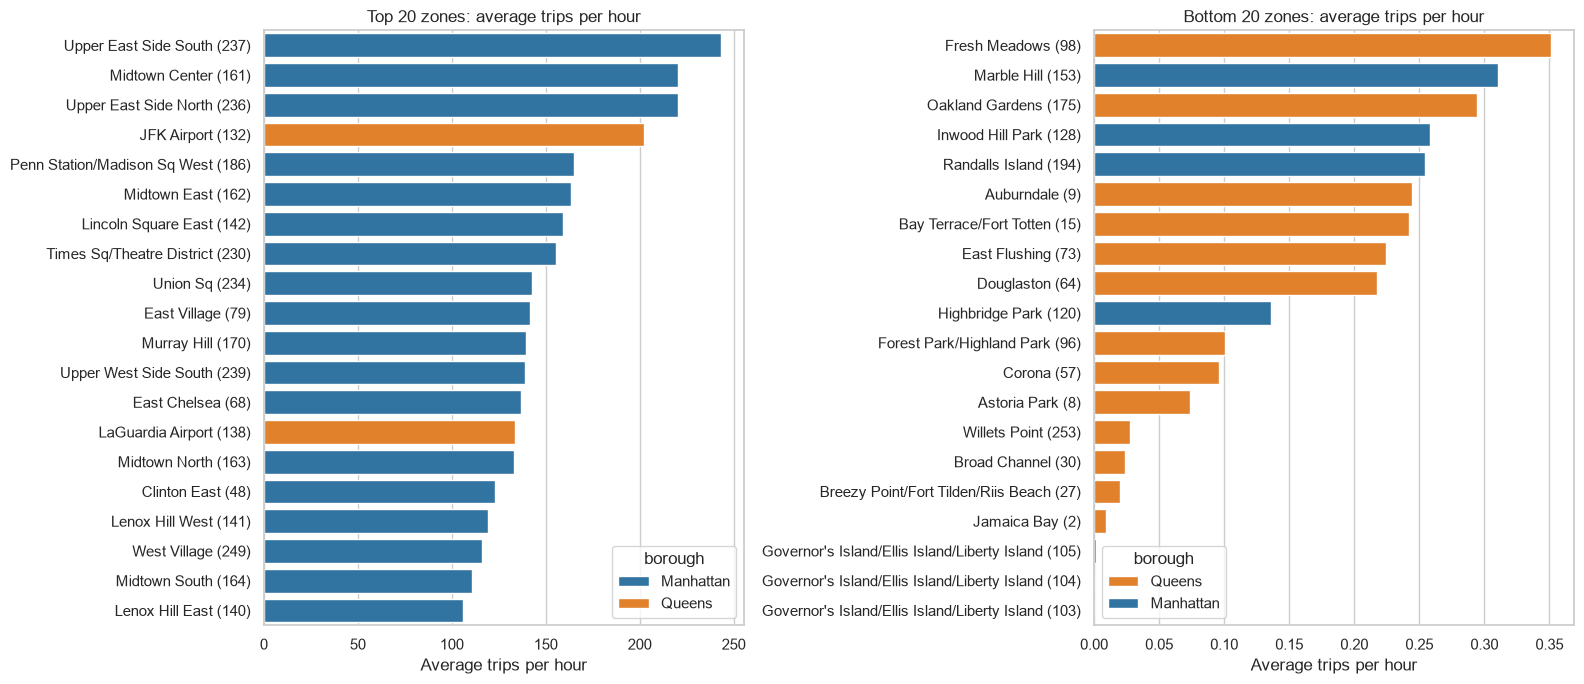

In [7]:
top20 = zone_stats.head(20)
bottom20 = zone_stats.tail(20)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(data=top20, y="zone_label", x="avg_per_hour", hue="borough",
            palette=BOROUGH_COLORS, dodge=False, ax=axes[0])
axes[0].set_title("Top 20 zones: average trips per hour")
axes[0].set_xlabel("Average trips per hour")
axes[0].set_ylabel("")

sns.barplot(data=bottom20, y="zone_label", x="avg_per_hour", hue="borough",
            palette=BOROUGH_COLORS, dodge=False, ax=axes[1])
axes[1].set_title("Bottom 20 zones: average trips per hour")
axes[1].set_xlabel("Average trips per hour")
axes[1].set_ylabel("")

save_fig("C1_top_bottom_zones")

In [8]:
# Totals by borough
borough_totals = zone_stats.groupby("borough")["total_trips"].sum()
print(borough_totals)
print()
print("Manhattan share of trips:", round(borough_totals["Manhattan"] / borough_totals.sum() * 100, 1), "%")
print()
print("Top 10 zones:")
print(zone_stats[["zone_label", "borough", "total_trips", "avg_per_hour"]].head(10).to_string(index=False))

borough
Manhattan    19679535
Queens        2048582
Name: total_trips, dtype: int64

Manhattan share of trips: 90.6 %

Top 10 zones:
                        zone_label   borough  total_trips  avg_per_hour
       Upper East Side South (237) Manhattan      1015744    243.233716
              Midtown Center (161) Manhattan       921353    220.630508
       Upper East Side North (236) Manhattan       919941    220.292385
                 JFK Airport (132)    Queens       844604    202.251916
Penn Station/Madison Sq West (186) Manhattan       690164    165.269157
                Midtown East (162) Manhattan       683449    163.661159
         Lincoln Square East (142) Manhattan       664996    159.242337
   Times Sq/Theatre District (230) Manhattan       648767    155.356082
                    Union Sq (234) Manhattan       596884    142.931992
                 East Village (79) Manhattan       590795    141.473898


**Finding:** Manhattan has 90.6% of trips. Busiest: Upper East Side South (243/hour), Midtown Center, Upper East Side North. JFK is the only Queens zone in the top 10.

## C2. Demand concentration (Pareto, Lorenz, Gini)

Zones needed for 50% of trips: 16 of 138
Zones needed for 80% of trips: 33 of 138


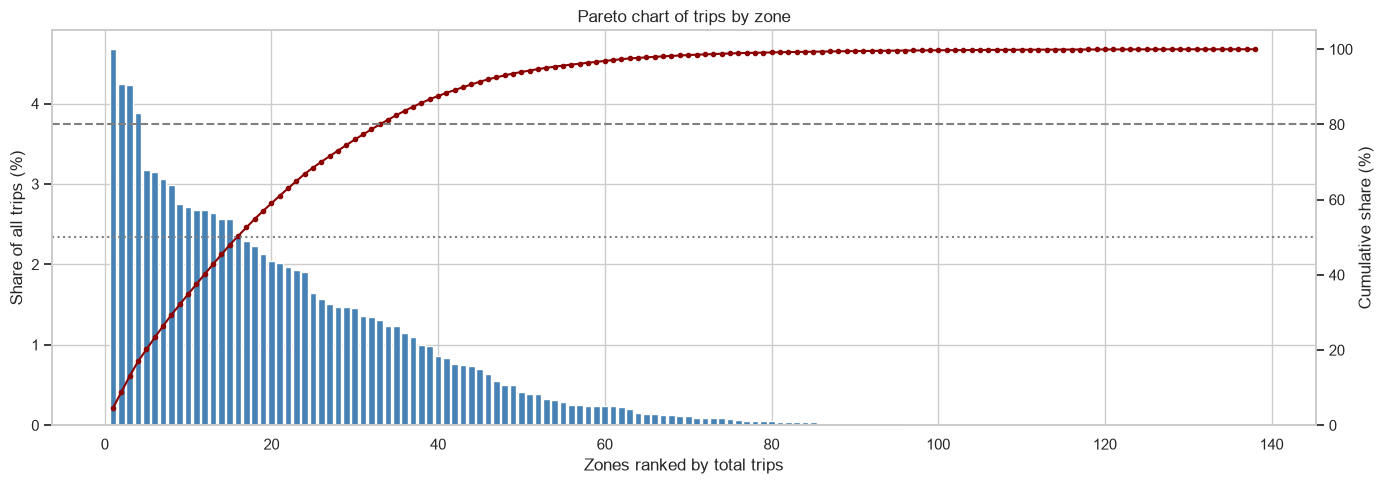

In [9]:
trips_sorted = zone_stats["total_trips"].values          # already sorted high to low
cum_share = trips_sorted.cumsum() / trips_sorted.sum()

zones_for_50 = (cum_share < 0.5).sum() + 1
zones_for_80 = (cum_share < 0.8).sum() + 1
print("Zones needed for 50% of trips:", zones_for_50, "of", len(zone_stats))
print("Zones needed for 80% of trips:", zones_for_80, "of", len(zone_stats))

fig, ax1 = plt.subplots(figsize=(14, 5))
x = np.arange(1, len(trips_sorted) + 1)
ax1.bar(x, trips_sorted / trips_sorted.sum() * 100, color="steelblue")
ax1.set_xlabel("Zones ranked by total trips")
ax1.set_ylabel("Share of all trips (%)")

ax2 = ax1.twinx()
ax2.plot(x, cum_share * 100, color="darkred", marker=".")
ax2.axhline(80, color="gray", linestyle="--")
ax2.axhline(50, color="gray", linestyle=":")
ax2.set_ylabel("Cumulative share (%)")
ax2.set_ylim(0, 105)
ax2.grid(False)

plt.title("Pareto chart of trips by zone")
save_fig("C2_pareto_chart")

All zones Gini: 0.709
Manhattan Gini: 0.486
Queens Gini: 0.844


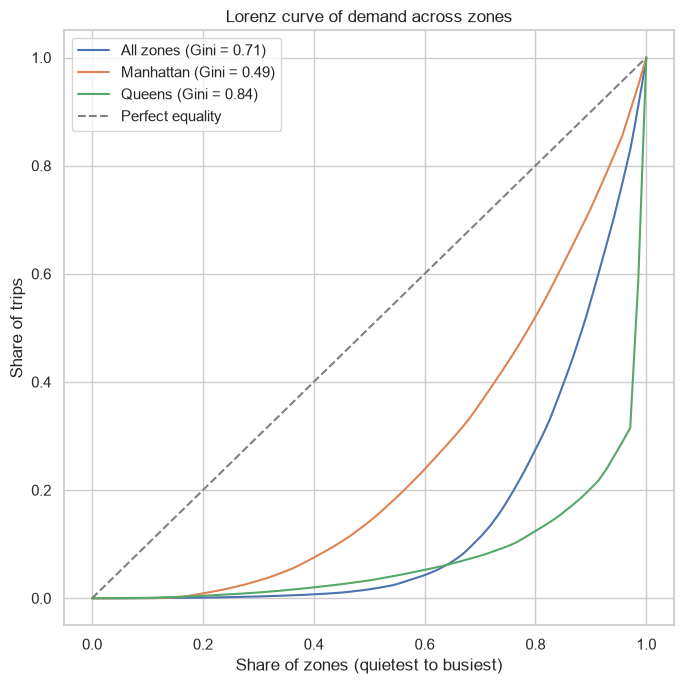

In [10]:
def gini(values):
    # Gini coefficient: 0 = perfectly equal, 1 = all demand in one zone
    values = np.sort(np.array(values, dtype=float))
    n = len(values)
    cum = np.cumsum(values)
    return (n + 1 - 2 * cum.sum() / cum[-1]) / n


def lorenz_points(values):
    values = np.sort(np.array(values, dtype=float))
    cum = np.cumsum(values) / values.sum()
    x = np.arange(0, len(values) + 1) / len(values)
    y = np.insert(cum, 0, 0)
    return x, y


plt.figure(figsize=(7, 7))
groups = {
    "All zones": zone_stats["total_trips"],
    "Manhattan": zone_stats[zone_stats["borough"] == "Manhattan"]["total_trips"],
    "Queens": zone_stats[zone_stats["borough"] == "Queens"]["total_trips"],
}
for name, values in groups.items():
    x, y = lorenz_points(values)
    g = gini(values)
    plt.plot(x, y, label=name + " (Gini = " + str(round(g, 2)) + ")")
    print(name, "Gini:", round(g, 3))

plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Perfect equality")
plt.xlabel("Share of zones (quietest to busiest)")
plt.ylabel("Share of trips")
plt.title("Lorenz curve of demand across zones")
plt.legend()
save_fig("C2_lorenz_curve")

**Finding:** 16 of 138 zones make up 50% of trips, 33 zones make up 80%. Gini: 0.71 overall, 0.49 Manhattan, 0.84 Queens.

## C6. Demand maps by time band

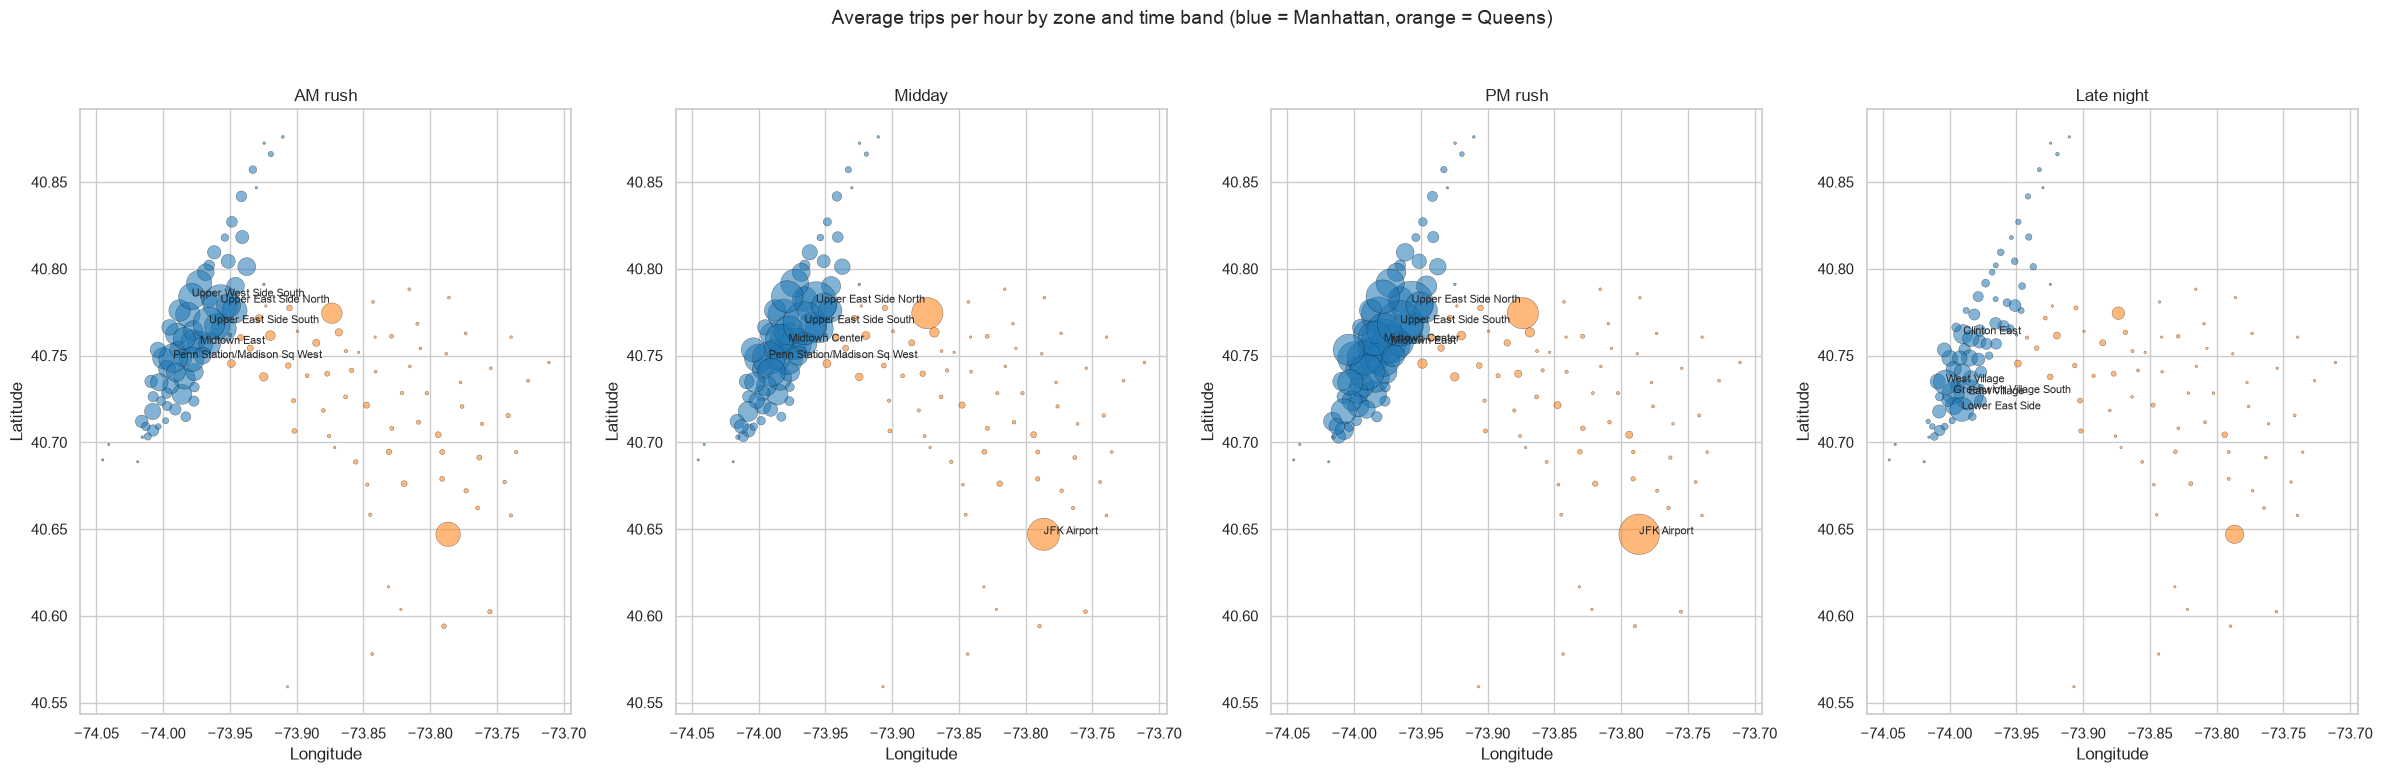

In [11]:
map_bands = ["AM rush", "Midday", "PM rush", "Late night"]

band_avg = df.groupby(["PULocationID", "time_band"])["trip_count"].mean().reset_index()
band_avg = band_avg.merge(zones, on="PULocationID")

fig, axes = plt.subplots(1, 4, figsize=(24, 8))
for i, band in enumerate(map_bands):
    ax = axes[i]
    data = band_avg[band_avg["time_band"] == band]
    ax.scatter(data["longitude"], data["latitude"],
               s=data["trip_count"] * 2.5 + 3,
               c=data["borough"].map(BOROUGH_COLORS),
               alpha=0.55, edgecolor="black", linewidth=0.3)

    top5 = data.sort_values("trip_count", ascending=False).head(5)
    for _, row in top5.iterrows():
        ax.annotate(row["zone_name"], (row["longitude"], row["latitude"]), fontsize=8)

    ax.set_title(band)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect(1.3)

plt.suptitle("Average trips per hour by zone and time band (blue = Manhattan, orange = Queens)", fontsize=14)
save_fig("C6_demand_maps_by_time_band")

In [12]:
# Top 5 zones in each time band
for band in TIME_BANDS:
    data = band_avg[band_avg["time_band"] == band].sort_values("trip_count", ascending=False).head(5)
    print(band + ":", ", ".join(data["zone_name"] + " (" + data["trip_count"].round(0).astype(int).astype(str) + ")"))

Late night: East Village (184), West Village (124), Lower East Side (117), Greenwich Village South (102), Clinton East (76)
Early morning: JFK Airport (98), Penn Station/Madison Sq West (71), Clinton East (56), Garment District (47), Upper East Side North (44)
AM rush: Upper East Side North (269), Upper East Side South (212), Penn Station/Madison Sq West (171), Upper West Side South (141), Midtown East (136)
Midday: Upper East Side South (381), Upper East Side North (365), Midtown Center (281), Penn Station/Madison Sq West (219), JFK Airport (214)
PM rush: Upper East Side South (425), Midtown Center (421), Upper East Side North (384), JFK Airport (339), Midtown East (310)
Evening: Midtown Center (341), JFK Airport (324), Times Sq/Theatre District (283), Lincoln Square East (263), Upper East Side South (257)


**Finding:** Hotspots move: Upper East/West Side in the AM rush, Midtown and JFK from midday, East Village / West Village / Lower East Side late at night.

## C7. Zone tiers (High ≥ 50, Medium 10-50, Low 1-10, Near-empty < 1 trips per hour)

In [13]:
def get_tier(avg):
    if avg < 1:
        return "Near-empty"
    elif avg < 10:
        return "Low"
    elif avg < 50:
        return "Medium"
    else:
        return "High"


zone_stats["tier"] = zone_stats["avg_per_hour"].apply(get_tier)
TIER_ORDER = ["High", "Medium", "Low", "Near-empty"]

tier_summary = zone_stats.groupby("tier").agg(
    zones=("PULocationID", "count"),
    manhattan_zones=("borough", lambda s: (s == "Manhattan").sum()),
    queens_zones=("borough", lambda s: (s == "Queens").sum()),
    total_trips=("total_trips", "sum"),
    avg_zero_share=("zero_share", "mean"),
).reindex(TIER_ORDER)
tier_summary["share_of_trips_%"] = (tier_summary["total_trips"] / tier_summary["total_trips"].sum() * 100).round(1)
tier_summary["avg_zero_share"] = tier_summary["avg_zero_share"].round(2)
tier_summary

,zones,manhattan_zones,queens_zones,total_trips,avg_zero_share,share_of_trips_%
tier,,,,,,
High,39,37,2,18842915,0.01,86.7
Medium,24,20,4,2356600,0.02,10.8
Low,35,4,31,463733,0.22,2.1
Near-empty,40,8,32,64869,0.74,0.3


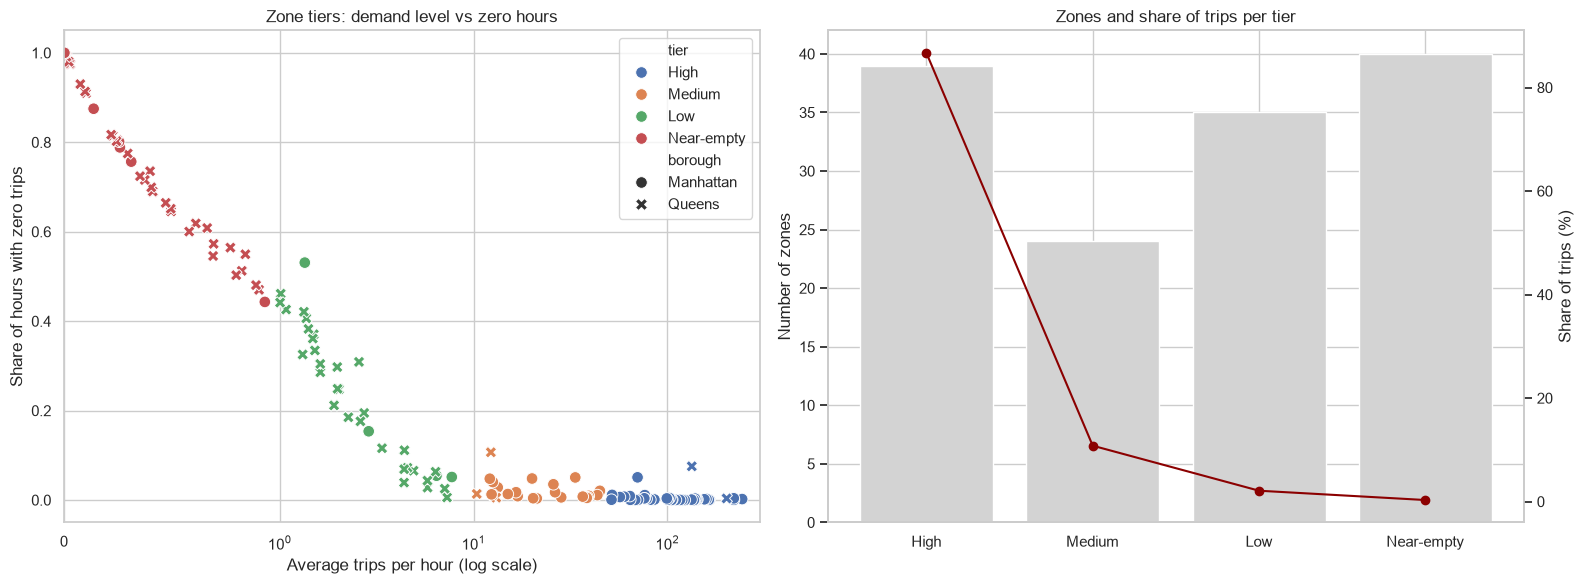

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=zone_stats, x="avg_per_hour", y="zero_share", hue="tier",
                hue_order=TIER_ORDER, style="borough", s=70, ax=axes[0])
axes[0].set_xscale("symlog", linthresh=1)
axes[0].set_xlim(0, 300)
axes[0].set_xlabel("Average trips per hour (log scale)")
axes[0].set_ylabel("Share of hours with zero trips")
axes[0].set_title("Zone tiers: demand level vs zero hours")

axes[1].bar(tier_summary.index, tier_summary["zones"], color="lightgray", label="Number of zones")
axes[1].set_ylabel("Number of zones")
ax2 = axes[1].twinx()
ax2.plot(tier_summary.index, tier_summary["share_of_trips_%"], color="darkred", marker="o", label="Share of trips (%)")
ax2.set_ylabel("Share of trips (%)")
ax2.grid(False)
axes[1].set_title("Zones and share of trips per tier")

save_fig("C7_zone_tiers")

**Finding:** 39 High zones carry 86.7% of trips. 40 Near-empty zones (mostly Queens) carry 0.3% and have zero trips in 74% of hours.

## C8. Zone clusters by weekly demand shape (k-means, holidays and near-empty zones left out)

In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

active_ids = zone_stats[zone_stats["tier"] != "Near-empty"]["PULocationID"]
normal_days = df[(df["is_holiday"] == False) & (df["PULocationID"].isin(active_ids))]

# Rows = zones, columns = (day_of_week, hour) -> 168 columns
weekly = normal_days.groupby(["PULocationID", "day_of_week", "hour"])["trip_count"].mean().unstack(["day_of_week", "hour"])

# Turn each row into shares so that only the shape matters
weekly_shape = weekly.div(weekly.sum(axis=1), axis=0)
print("Zones clustered:", weekly_shape.shape[0], "| profile length:", weekly_shape.shape[1])

Zones clustered: 98 | profile length: 168


k = 2 | silhouette = 0.276
k = 3 | silhouette = 0.301
k = 4 | silhouette = 0.266
k = 5 | silhouette = 0.232
k = 6 | silhouette = 0.236
k = 7 | silhouette = 0.22
k = 8 | silhouette = 0.219


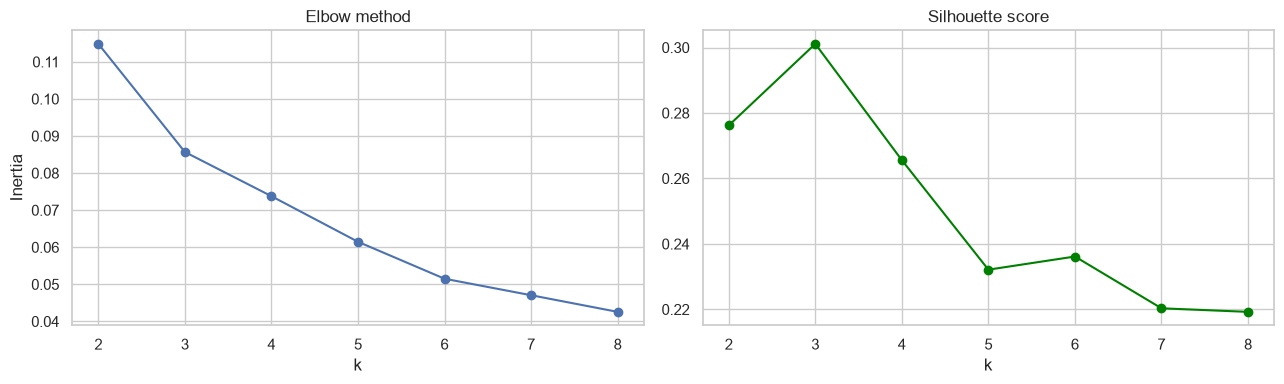

In [16]:
# Try k = 2 to 8 and compare inertia (elbow) and silhouette score
k_values = range(2, 9)
inertias = []
silhouettes = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = model.fit_predict(weekly_shape)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(weekly_shape, labels))
    print("k =", k, "| silhouette =", round(silhouettes[-1], 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_values), silhouettes, marker="o", color="green")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
save_fig("C8_choosing_k")

In [17]:
# k = 3 has the highest silhouette score. k = 4 only splits off a single zone (Maspeth),
# so 3 clusters is the clearest grouping.
K = 3

# Names chosen after looking at the weekly shapes and the zones in each cluster below
CLUSTER_NAMES = {
    0: "Residential (morning commute)",
    1: "Nightlife (late night and weekends)",
    2: "Core business and airports (daytime)",
}

kmeans = KMeans(n_clusters=K, n_init=20, random_state=42)
cluster_ids = kmeans.fit_predict(weekly_shape)
cluster_table = pd.DataFrame({"PULocationID": weekly_shape.index, "cluster": cluster_ids})
cluster_table = cluster_table.merge(zone_stats[["PULocationID", "zone_name", "zone_label", "borough",
                                                "service_zone", "total_trips", "tier"]], on="PULocationID")

# Show the busiest zones in each cluster to help name it
for c in range(K):
    members = cluster_table[cluster_table["cluster"] == c].sort_values("total_trips", ascending=False)
    print(CLUSTER_NAMES[c], "-", len(members), "zones:", ", ".join(members["zone_name"].head(8)))

Residential (morning commute) - 30 zones: Yorkville East, East Harlem North, Central Harlem North, Washington Heights South, Astoria, Hamilton Heights, Sunnyside, Jackson Heights
Nightlife (late night and weekends) - 10 zones: East Village, West Village, Greenwich Village South, Lower East Side, Little Italy/NoLiTa, Meatpacking/West Village West, Alphabet City, Seaport
Core business and airports (daytime) - 58 zones: Upper East Side South, Midtown Center, Upper East Side North, JFK Airport, Penn Station/Madison Sq West, Midtown East, Lincoln Square East, Times Sq/Theatre District


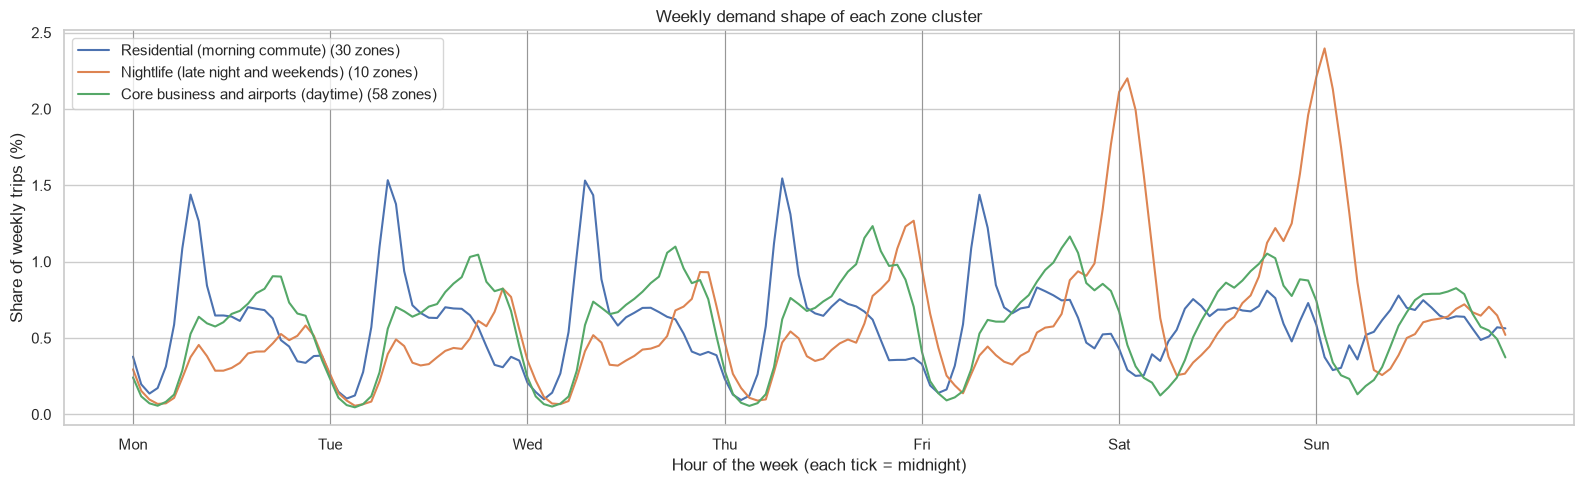

In [18]:
# Average weekly shape of each cluster
fig, ax = plt.subplots(figsize=(16, 5))
for c in range(K):
    member_ids = cluster_table[cluster_table["cluster"] == c]["PULocationID"]
    avg_shape = weekly_shape.loc[member_ids].mean() * 100
    ax.plot(range(168), avg_shape.values, label=CLUSTER_NAMES[c] + " (" + str(len(member_ids)) + " zones)")

ax.set_xticks(range(0, 168, 24))
ax.set_xticklabels(DAY_NAMES)
for x in range(0, 168, 24):
    ax.axvline(x, color="gray", linewidth=0.5)
ax.set_xlabel("Hour of the week (each tick = midnight)")
ax.set_ylabel("Share of weekly trips (%)")
ax.set_title("Weekly demand shape of each zone cluster")
ax.legend()
save_fig("C8_cluster_weekly_profiles")

In [19]:
cluster_table["cluster_name"] = cluster_table["cluster"].map(CLUSTER_NAMES)

cluster_summary = cluster_table.groupby("cluster_name").agg(
    zones=("PULocationID", "count"),
    manhattan=("borough", lambda s: (s == "Manhattan").sum()),
    queens=("borough", lambda s: (s == "Queens").sum()),
    total_trips=("total_trips", "sum"),
)
cluster_summary["share_of_trips_%"] = (cluster_summary["total_trips"] / zone_stats["total_trips"].sum() * 100).round(1)
cluster_summary

,zones,manhattan,queens,total_trips,share_of_trips_%
cluster_name,,,,,
Core business and airports (daytime),58,46,12,18314351,84.3
Nightlife (late night and weekends),10,8,2,2315770,10.7
Residential (morning commute),30,7,23,1033127,4.8


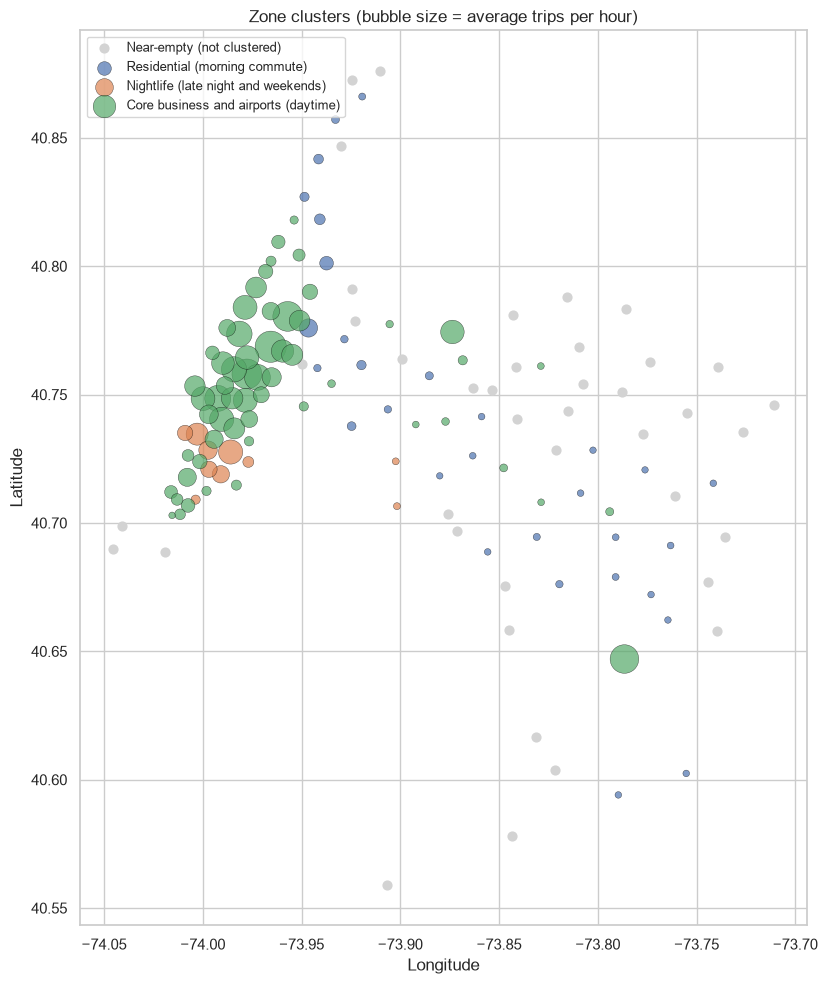

In [20]:
# Map of the clusters (near-empty zones in light gray)
map_data = zone_stats.merge(cluster_table[["PULocationID", "cluster_name"]], on="PULocationID", how="left")
map_data["cluster_name"] = map_data["cluster_name"].fillna("Near-empty (not clustered)")

plt.figure(figsize=(10, 10))
empty = map_data[map_data["cluster_name"] == "Near-empty (not clustered)"]
plt.scatter(empty["longitude"], empty["latitude"], color="lightgray", s=40, label="Near-empty (not clustered)")

for name in CLUSTER_NAMES.values():
    data = map_data[map_data["cluster_name"] == name]
    plt.scatter(data["longitude"], data["latitude"], s=data["avg_per_hour"] * 2 + 20,
                alpha=0.7, edgecolor="black", linewidth=0.3, label=name)

plt.gca().set_aspect(1.3)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Zone clusters (bubble size = average trips per hour)")
plt.legend(loc="upper left", fontsize=9)
save_fig("C8_cluster_map")

**Finding:** 3 zone types: Core business and airports (58 zones, 84% of trips, daytime), Nightlife (10 zones, 11%, Fri/Sat nights), Residential (30 zones, 5%, weekday 07-09 peak).

## C10. Demand correlation between the 30 busiest zones

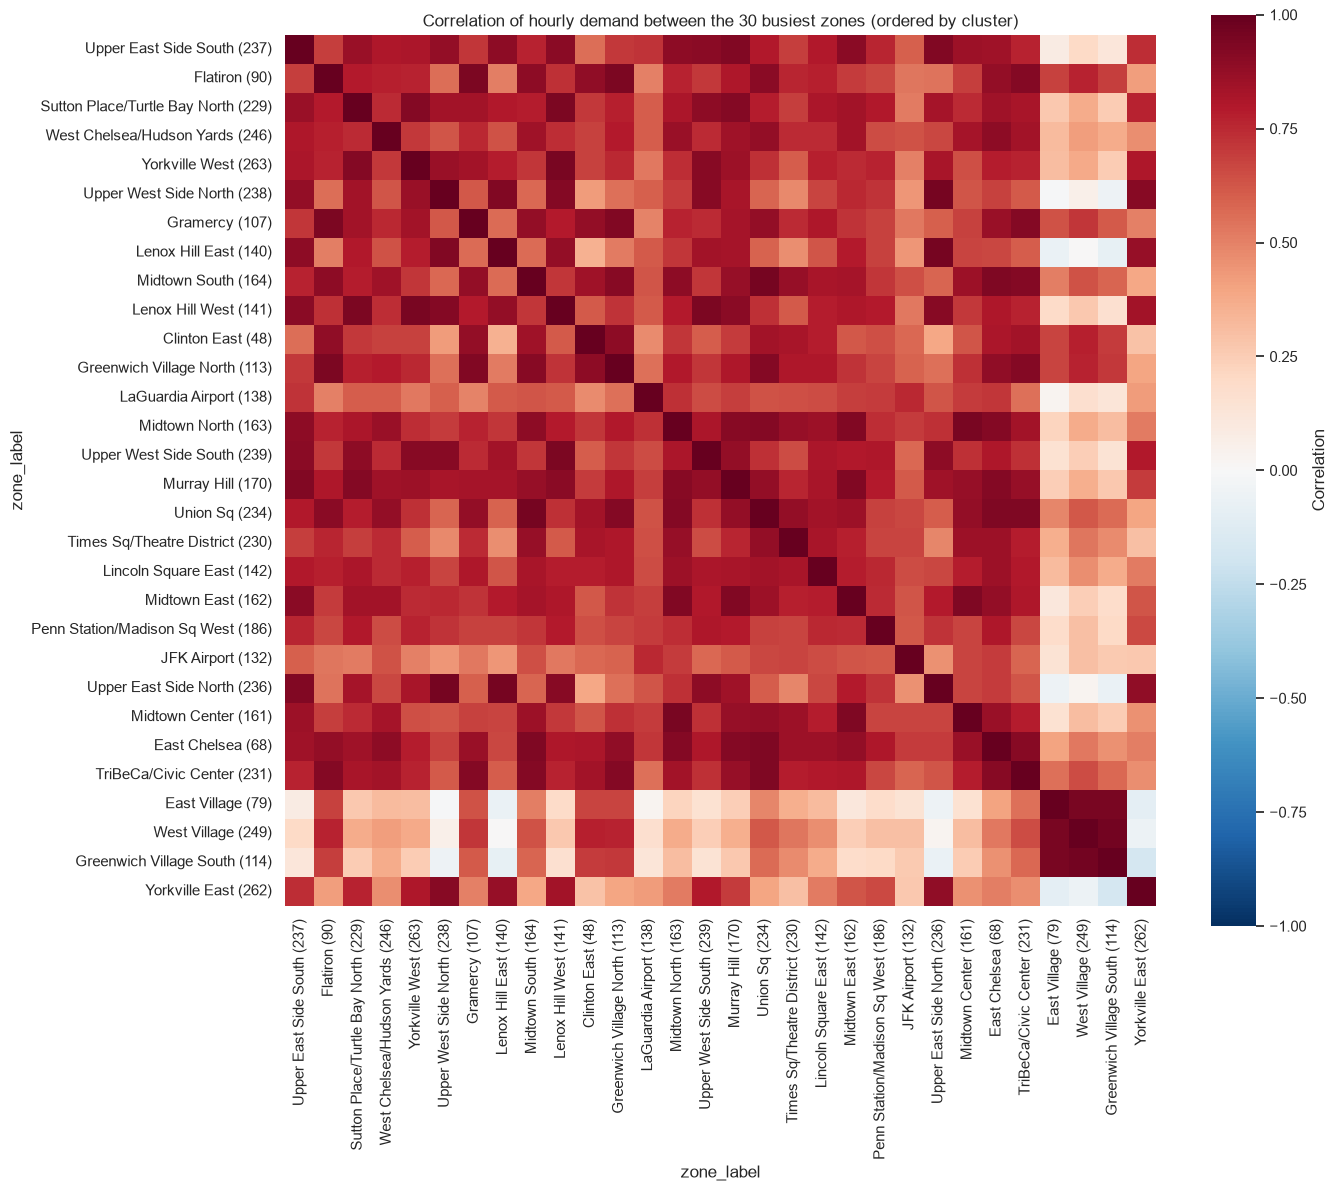

In [21]:
top30 = zone_stats.head(30)[["PULocationID", "zone_label"]].merge(cluster_table[["PULocationID", "cluster_name"]], on="PULocationID")
top30 = top30.sort_values("cluster_name")

hourly_top30 = df[df["PULocationID"].isin(top30["PULocationID"])].pivot_table(
    index="pickup_hour", columns="zone_label", values="trip_count")
hourly_top30 = hourly_top30[top30["zone_label"]]   # order the columns by cluster

zone_corr = hourly_top30.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(zone_corr, cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Correlation"}, xticklabels=True, yticklabels=True)
plt.title("Correlation of hourly demand between the 30 busiest zones (ordered by cluster)")
save_fig("C10_zone_correlation_heatmap")

In [22]:
# Average correlation for pairs in the same cluster vs different clusters
same_cluster = []
diff_cluster = []
labels = list(top30["zone_label"])
clusters = list(top30["cluster_name"])
for i in range(len(labels)):
    for j in range(i + 1, len(labels)):
        value = zone_corr.loc[labels[i], labels[j]]
        if clusters[i] == clusters[j]:
            same_cluster.append(value)
        else:
            diff_cluster.append(value)

print("Average correlation, same cluster:     ", round(np.mean(same_cluster), 2))
print("Average correlation, different cluster:", round(np.mean(diff_cluster), 2))

Average correlation, same cluster:      0.75
Average correlation, different cluster: 0.38


**Finding:** Average correlation is 0.75 within a cluster and 0.38 between clusters.

## H1. Variability per zone (CV = std / mean)

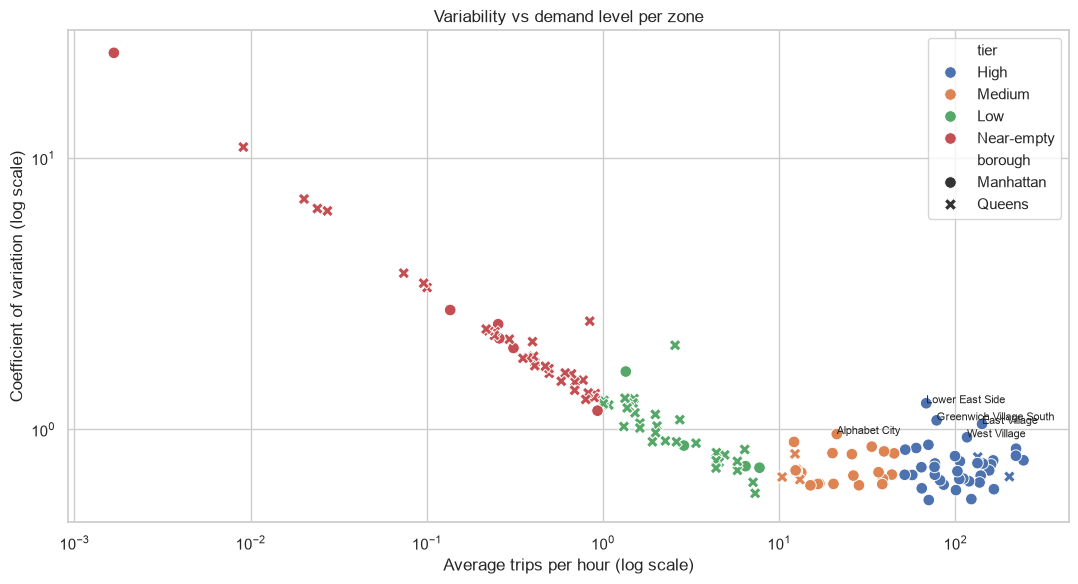

In [23]:
zone_std = df.groupby("PULocationID")["trip_count"].std().rename("std_per_hour").reset_index()
zone_stats = zone_stats.merge(zone_std, on="PULocationID")
zone_stats["cv"] = zone_stats["std_per_hour"] / zone_stats["avg_per_hour"]

plot_data = zone_stats[zone_stats["avg_per_hour"] > 0]

plt.figure(figsize=(11, 6))
sns.scatterplot(data=plot_data, x="avg_per_hour", y="cv", hue="tier", hue_order=TIER_ORDER, style="borough", s=70)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Average trips per hour (log scale)")
plt.ylabel("Coefficient of variation (log scale)")
plt.title("Variability vs demand level per zone")

# Label the 5 most variable zones among High and Medium tier
busy = plot_data[plot_data["tier"].isin(["High", "Medium"])].sort_values("cv", ascending=False).head(5)
for _, row in busy.iterrows():
    plt.annotate(row["zone_name"], (row["avg_per_hour"], row["cv"]), fontsize=8)
save_fig("H1_cv_vs_mean")

In [24]:
print("Median CV by tier:")
print(zone_stats.groupby("tier")["cv"].median().reindex(TIER_ORDER).round(2))
print()
print("Most variable High/Medium zones:")
print(busy[["zone_label", "avg_per_hour", "cv"]].round(2).to_string(index=False))

Median CV by tier:
tier
High          0.73
Medium        0.70
Low           0.97
Near-empty    1.93
Name: cv, dtype: float64

Most variable High/Medium zones:
                   zone_label  avg_per_hour   cv
        Lower East Side (148)         68.23 1.25
Greenwich Village South (114)         78.16 1.08
            East Village (79)        141.47 1.05
            Alphabet City (4)         21.21 0.96
           West Village (249)        116.28 0.94


**Finding:** Busy zones are more stable (median CV ≈ 0.7) than near-empty ones (1.93). Nightlife zones are the most variable busy zones.

## H2. Demand classes (Syntetos-Boylan: ADI cut-off 1.32, CV² cut-off 0.49)

In [25]:
ADI_CUT = 1.32
CV2_CUT = 0.49

rows = []
for zone_id, group in df.groupby("PULocationID"):
    counts = group["trip_count"]
    nonzero = counts[counts > 0]

    if len(nonzero) < 2:
        rows.append({"PULocationID": zone_id, "adi": np.nan, "cv2": np.nan, "demand_class": "No demand"})
        continue

    adi = len(counts) / len(nonzero)
    cv2 = (nonzero.std() / nonzero.mean()) ** 2

    if adi < ADI_CUT and cv2 < CV2_CUT:
        demand_class = "Smooth"
    elif adi < ADI_CUT:
        demand_class = "Erratic"
    elif cv2 < CV2_CUT:
        demand_class = "Intermittent"
    else:
        demand_class = "Lumpy"

    rows.append({"PULocationID": zone_id, "adi": adi, "cv2": cv2, "demand_class": demand_class})

sb_table = pd.DataFrame(rows)
zone_stats = zone_stats.merge(sb_table, on="PULocationID")

print(zone_stats["demand_class"].value_counts())
print()
print(pd.crosstab(zone_stats["tier"], zone_stats["demand_class"]).reindex(TIER_ORDER))

demand_class
Smooth          46
Intermittent    43
Erratic         35
Lumpy           12
No demand        2
Name: count, dtype: int64

demand_class  Erratic  Intermittent  Lumpy  No demand  Smooth
tier                                                         
High               21             0      0          0      18
Medium              7             0      0          0      17
Low                 7             7     10          0      11
Near-empty          0            36      2          2       0


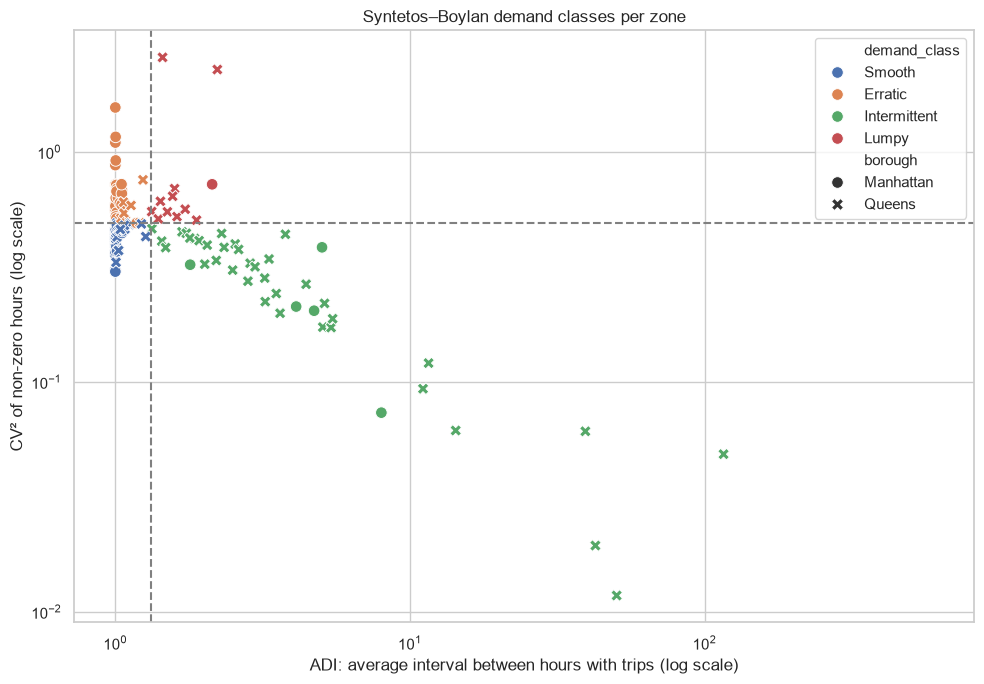

In [26]:
CLASS_ORDER = ["Smooth", "Erratic", "Intermittent", "Lumpy"]
plot_data = zone_stats[zone_stats["demand_class"] != "No demand"]

plt.figure(figsize=(10, 7))
sns.scatterplot(data=plot_data, x="adi", y="cv2", hue="demand_class", hue_order=CLASS_ORDER, style="borough", s=70)
plt.axvline(ADI_CUT, color="gray", linestyle="--")
plt.axhline(CV2_CUT, color="gray", linestyle="--")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("ADI: average interval between hours with trips (log scale)")
plt.ylabel("CV² of non-zero hours (log scale)")
plt.title("Syntetos–Boylan demand classes per zone")
save_fig("H2_demand_classes")

**Finding:** 46 Smooth, 35 Erratic, 43 Intermittent, 12 Lumpy. All High/Medium zones are Smooth or Erratic; 36 of 40 Near-empty zones are Intermittent.

## H6. Predictability by hour and weekday (CV of each slot across weeks)

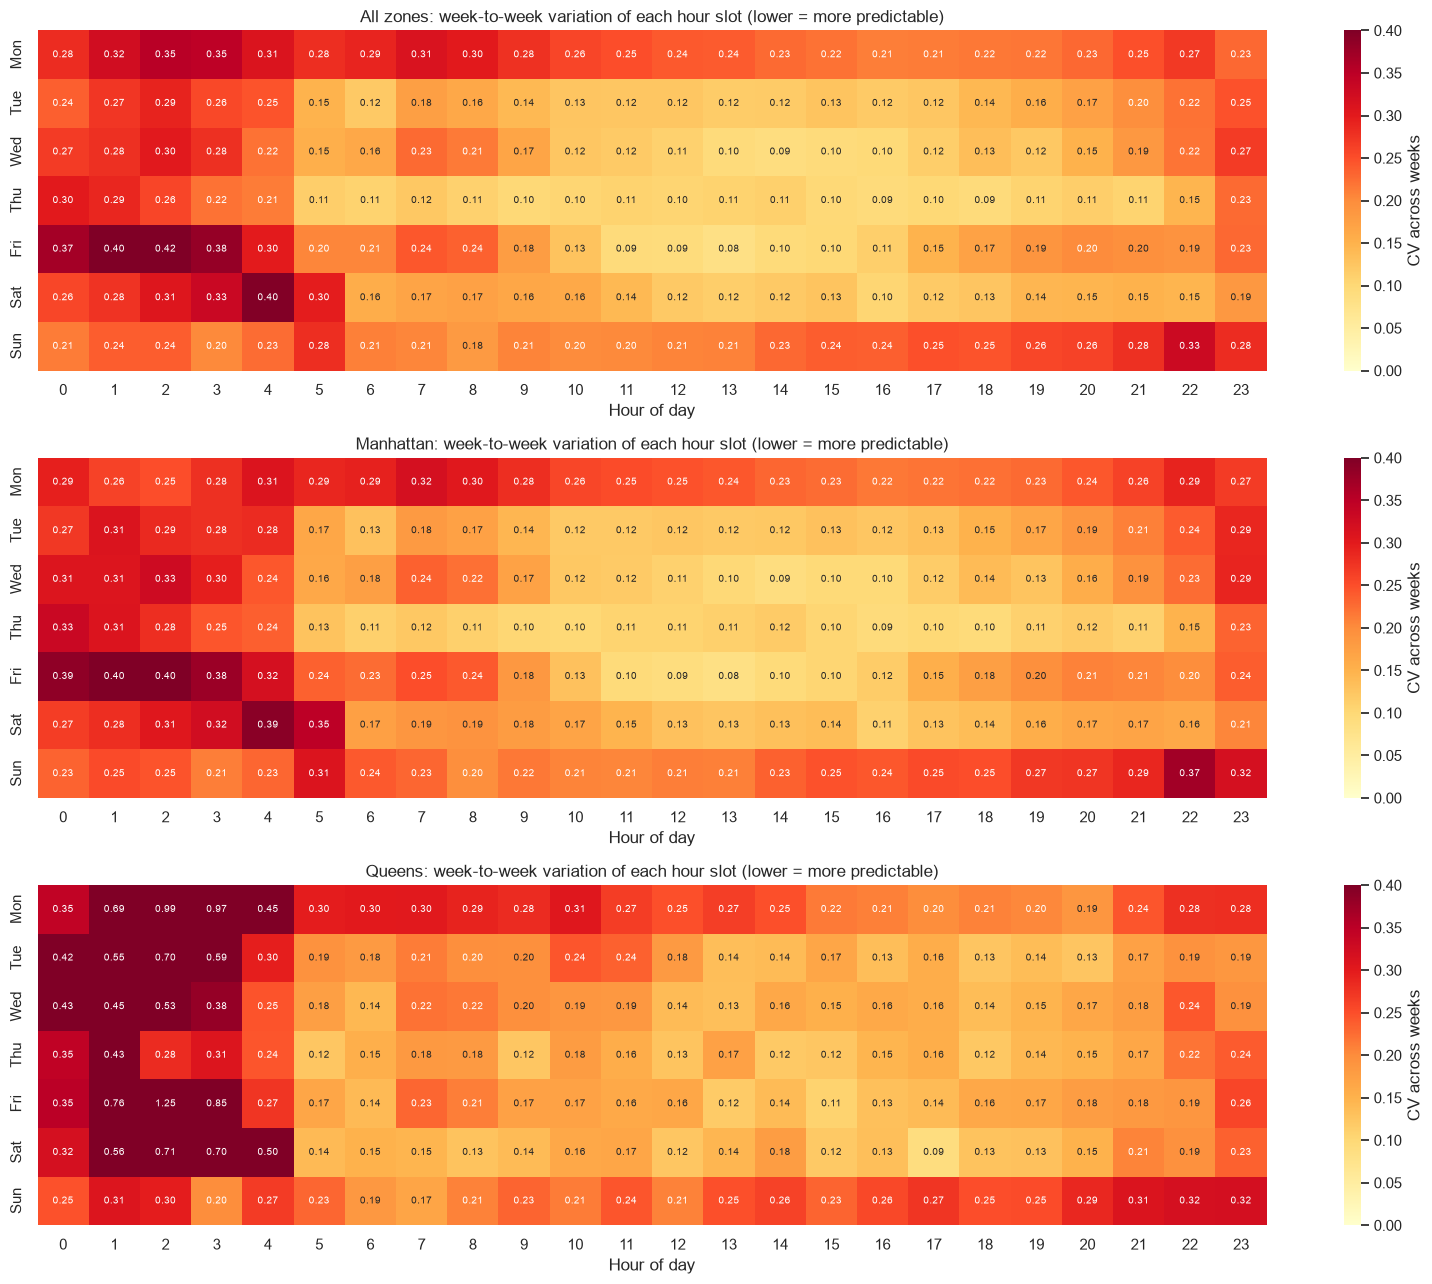

In [27]:
normal_hours = df[(df["is_holiday"] == False) & (df["is_dst_hour"] == False)]


def slot_cv_table(data):
    # Total trips per clock hour, then CV of each (weekday, hour) slot across weeks
    totals = data.groupby(["pickup_hour", "day_of_week", "hour"])["trip_count"].sum().reset_index()
    cv = totals.groupby(["day_of_week", "hour"])["trip_count"].agg(lambda s: s.std() / s.mean())
    table = cv.unstack("hour")
    table.index = DAY_NAMES
    return table


fig, axes = plt.subplots(3, 1, figsize=(16, 13))
groups = {
    "All zones": normal_hours,
    "Manhattan": normal_hours[normal_hours["borough"] == "Manhattan"],
    "Queens": normal_hours[normal_hours["borough"] == "Queens"],
}
slot_cv = {}
for i, (name, data) in enumerate(groups.items()):
    slot_cv[name] = slot_cv_table(data)
    sns.heatmap(slot_cv[name], cmap="YlOrRd", annot=True, fmt=".2f", annot_kws={"size": 7},
                vmin=0, vmax=0.4, ax=axes[i], cbar_kws={"label": "CV across weeks"})
    axes[i].set_title(name + ": week-to-week variation of each hour slot (lower = more predictable)")
    axes[i].set_xlabel("Hour of day")
    axes[i].set_ylabel("")
save_fig("H6_predictability_heatmap")

In [28]:
all_cv = slot_cv["All zones"].stack()
print("Most predictable slots:")
print(all_cv.sort_values().head(5).round(3))
print()
print("Least predictable slots:")
print(all_cv.sort_values(ascending=False).head(5).round(3))
print()
print("Average slot CV  -  Manhattan:", round(slot_cv["Manhattan"].values.mean(), 3),
      "| Queens:", round(slot_cv["Queens"].values.mean(), 3))

Most predictable slots:
     hour
Fri  13      0.083
Wed  14      0.091
Fri  12      0.094
Thu  18      0.094
     16      0.095
dtype: float64

Least predictable slots:
     hour
Fri  2       0.425
     1       0.402
Sat  4       0.398
Fri  3       0.382
     0       0.370
dtype: float64

Average slot CV  -  Manhattan: 0.206 | Queens: 0.253


**Finding:** Weekday daytime is most predictable (CV ≈ 0.1). Late nights, Mondays, Sundays and Queens are the least predictable.

## Save zone tables

In [29]:
tier_columns = ["PULocationID", "zone_name", "borough", "service_zone", "total_trips",
                "avg_per_hour", "zero_share", "tier", "cv", "adi", "cv2", "demand_class"]
zone_stats[tier_columns].round(4).to_csv(TABLE_DIR + "/zone_tiers.csv", index=False)

clusters_out = zone_stats[["PULocationID", "zone_name", "borough", "service_zone", "tier"]].merge(
    cluster_table[["PULocationID", "cluster", "cluster_name"]], on="PULocationID", how="left")
clusters_out["cluster"] = clusters_out["cluster"].astype("Int64")   # whole numbers; blank for near-empty zones
clusters_out["cluster_name"] = clusters_out["cluster_name"].fillna("Near-empty (not clustered)")
clusters_out.to_csv(TABLE_DIR + "/zone_clusters.csv", index=False)

print("Saved zone_tiers.csv and zone_clusters.csv")

Saved zone_tiers.csv and zone_clusters.csv


---
# 2. Demand over time and anomalies (#60)

In [30]:
# Federal holidays in the data (Labor Day, 1 Sep, is in the dropped first week)
HOLIDAYS = {
    "2025-10-13": "Columbus Day",
    "2025-11-11": "Veterans Day",
    "2025-11-27": "Thanksgiving",
    "2025-12-25": "Christmas",
    "2026-01-01": "New Year's Day",
    "2026-01-19": "MLK Day",
    "2026-02-16": "Presidents' Day",
}
DST_HOUR = pd.Timestamp("2025-11-02 01:00:00")

# Total trips per clock hour: all zones and each borough
hourly = df.groupby("pickup_hour")["trip_count"].sum()
hourly_manhattan = df[df["borough"] == "Manhattan"].groupby("pickup_hour")["trip_count"].sum()
hourly_queens = df[df["borough"] == "Queens"].groupby("pickup_hour")["trip_count"].sum()

# Total trips per day
daily = df.groupby("date")["trip_count"].sum()
print("Hours:", len(hourly), "| Days:", len(daily))

Hours: 4176 | Days: 174


## D1. Hourly demand (red dot = DST hour)

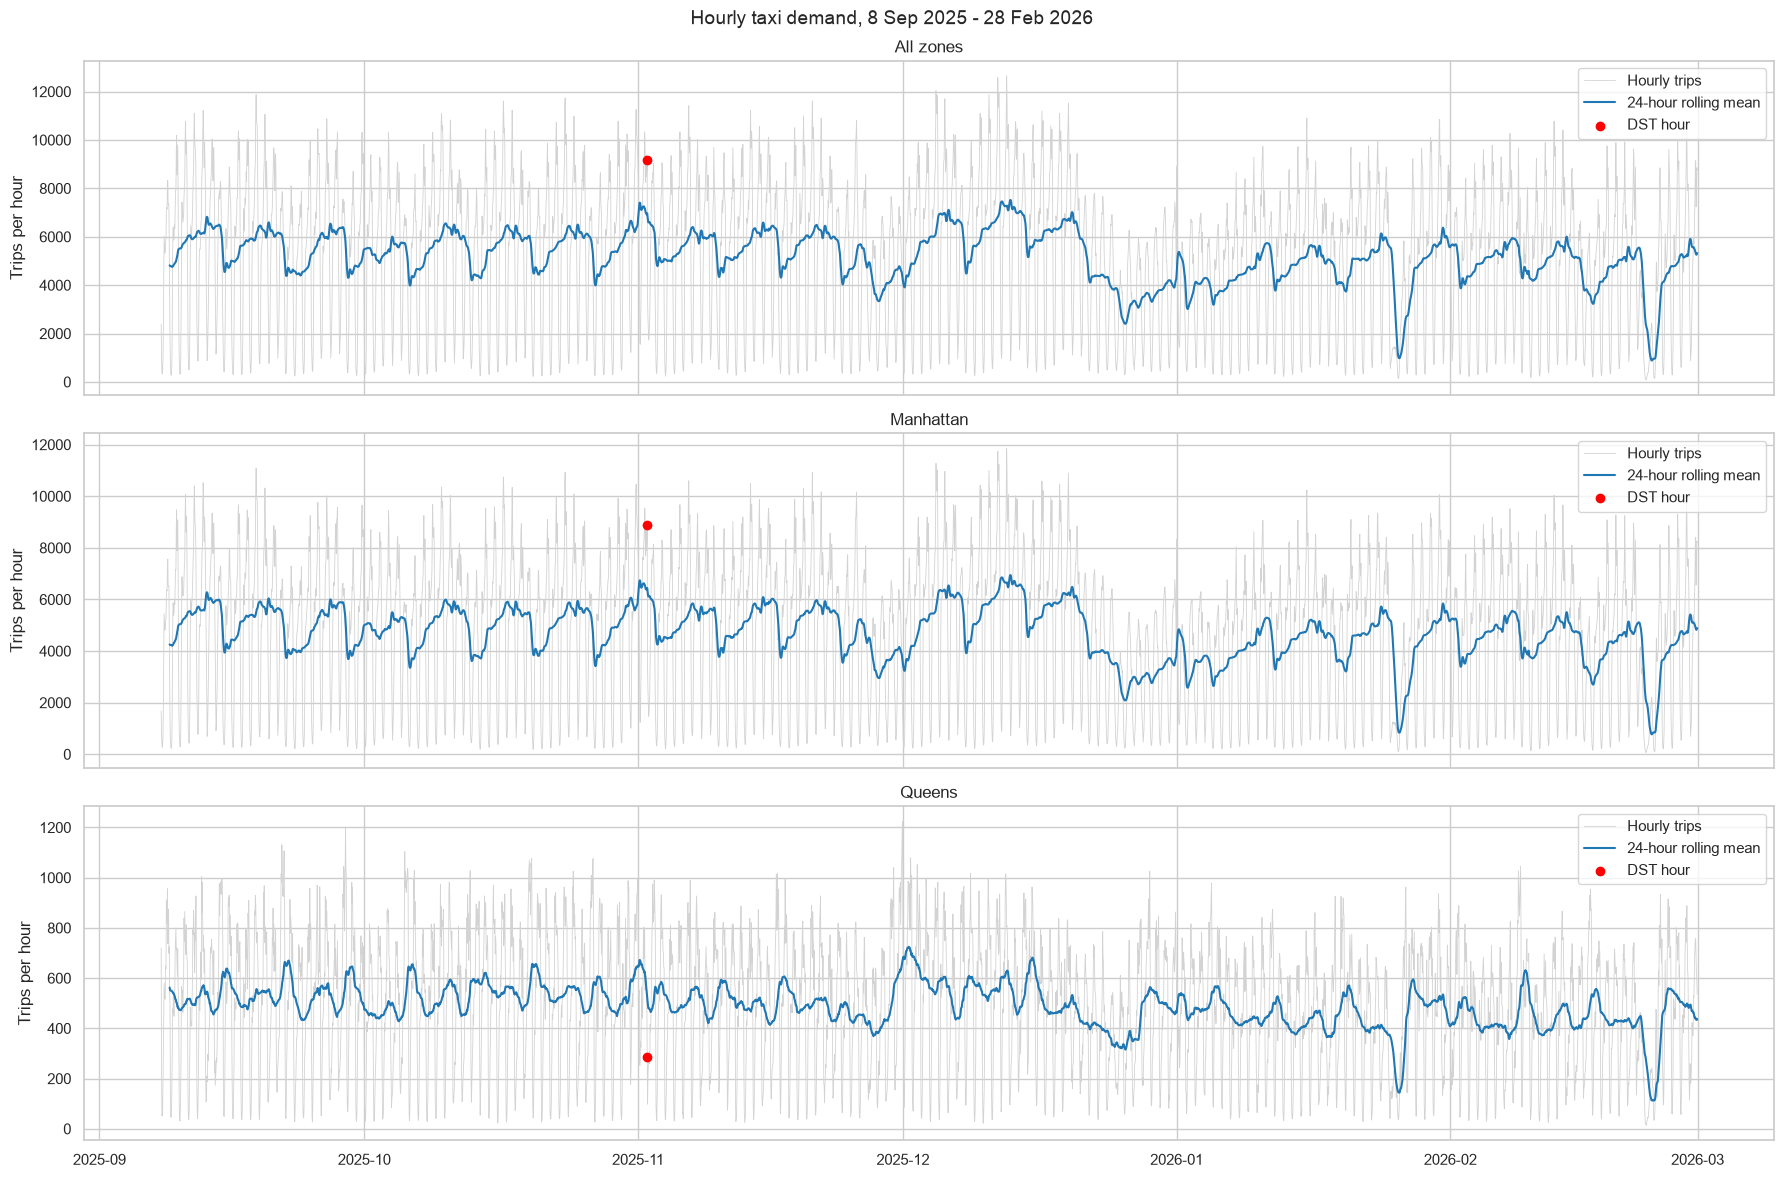

In [31]:
fig, axes = plt.subplots(3, 1, figsize=(18, 12), sharex=True)
series_list = [("All zones", hourly), ("Manhattan", hourly_manhattan), ("Queens", hourly_queens)]

for i, (name, series) in enumerate(series_list):
    axes[i].plot(series.index, series.values, color="lightgray", linewidth=0.6, label="Hourly trips")
    axes[i].plot(series.index, series.rolling(24).mean().values, color="tab:blue", linewidth=1.5, label="24-hour rolling mean")
    axes[i].scatter([DST_HOUR], [series[DST_HOUR]], color="red", zorder=5, label="DST hour")
    axes[i].set_title(name)
    axes[i].set_ylabel("Trips per hour")
    axes[i].legend(loc="upper right")

plt.suptitle("Hourly taxi demand, 8 Sep 2025 - 28 Feb 2026", fontsize=14)
save_fig("D1_hourly_demand")

In [32]:
print("Average trips per hour:", round(hourly.mean()))
print("Busiest hour:", hourly.idxmax(), "-", hourly.max(), "trips")
print("Quietest hour:", hourly.idxmin(), "-", hourly.min(), "trips")

Average trips per hour: 5203
Busiest hour: 2025-12-12 18:00:00 - 12648 trips
Quietest hour: 2026-02-23 04:00:00 - 87 trips


**Finding:** 5,203 trips per hour on average. Busiest hour: Fri 12 Dec 18:00 (12,648). Quietest: 23 Feb 04:00 (87, snowstorm).

## D2. Daily demand, trend and calendar heatmap

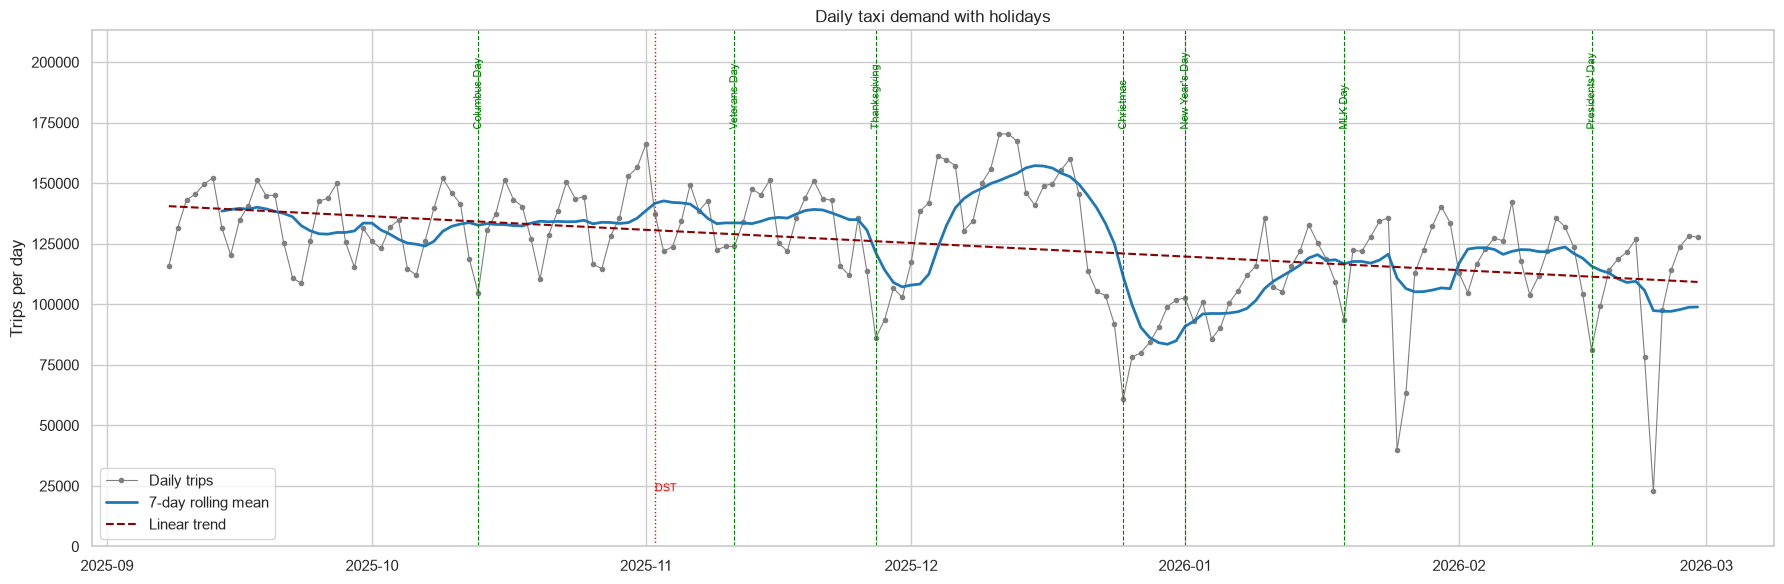

Trend: about -1266 trips per day lost each week
Average trips per day, first 4 weeks: 132729
Average trips per day, last 4 weeks:  112806
Change: -15.0 %


In [33]:
fig, ax = plt.subplots(figsize=(18, 6))
ax.plot(daily.index, daily.values, color="gray", marker=".", linewidth=0.8, label="Daily trips")
ax.plot(daily.index, daily.rolling(7).mean().values, color="tab:blue", linewidth=2, label="7-day rolling mean")

for day, name in HOLIDAYS.items():
    day = pd.Timestamp(day)
    ax.axvline(day, color="green", linestyle="--", linewidth=0.8)
    ax.text(day, daily.max() * 1.01, name, rotation=90, fontsize=8, va="bottom", ha="center", color="green")
ax.axvline(DST_HOUR.normalize(), color="red", linestyle=":", linewidth=1)
ax.text(DST_HOUR.normalize(), daily.min(), "DST", color="red", fontsize=8)

# Straight-line trend over the whole period
day_number = np.arange(len(daily))
slope, intercept = np.polyfit(day_number, daily.values, 1)
ax.plot(daily.index, intercept + slope * day_number, color="darkred", linestyle="--", label="Linear trend")

ax.set_ylabel("Trips per day")
ax.set_ylim(0, daily.max() * 1.25)
ax.set_title("Daily taxi demand with holidays")
ax.legend(loc="lower left")
save_fig("D2_daily_demand_trend")

print("Trend: about", round(slope * 7), "trips per day lost each week")
first_4_weeks = daily.iloc[:28].mean()
last_4_weeks = daily.iloc[-28:].mean()
print("Average trips per day, first 4 weeks:", round(first_4_weeks))
print("Average trips per day, last 4 weeks: ", round(last_4_weeks))
print("Change:", round((last_4_weeks / first_4_weeks - 1) * 100, 1), "%")

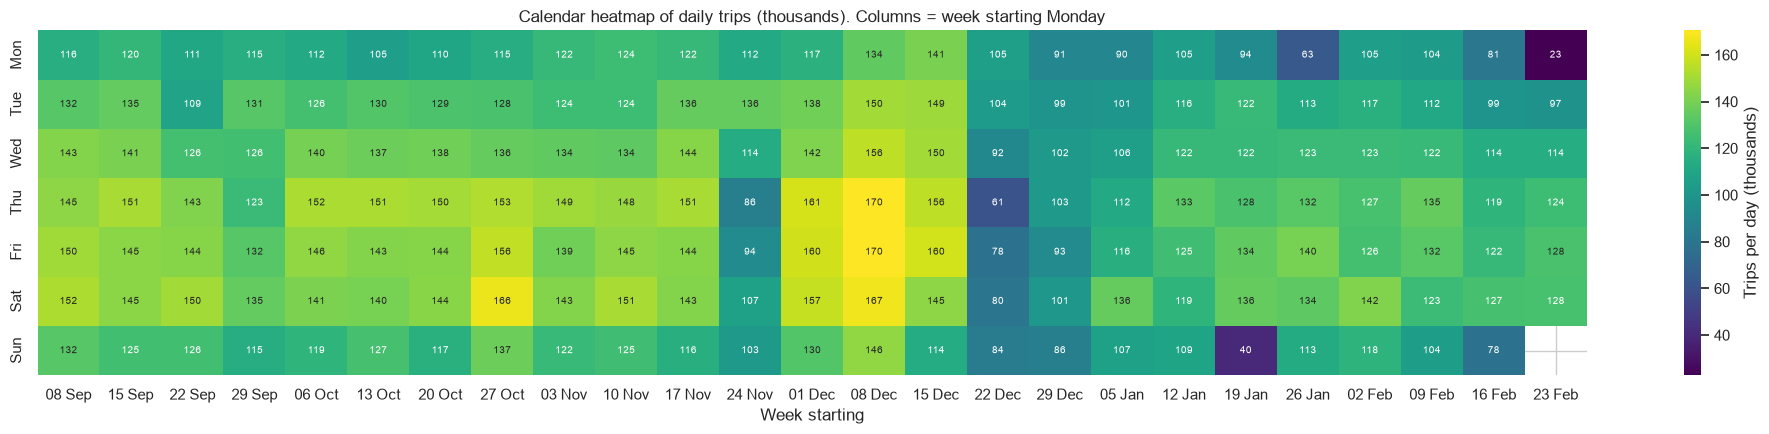

In [34]:
# Calendar heatmap: one cell per day
calendar = daily.reset_index()
calendar.columns = ["date", "trips"]
calendar["weekday"] = calendar["date"].dt.dayofweek
calendar["week_start"] = calendar["date"] - pd.to_timedelta(calendar["weekday"], unit="D")

calendar_grid = calendar.pivot(index="weekday", columns="week_start", values="trips")
calendar_grid.index = DAY_NAMES
calendar_grid.columns = [d.strftime("%d %b") for d in calendar_grid.columns]

plt.figure(figsize=(20, 4.5))
sns.heatmap(calendar_grid / 1000, cmap="viridis", annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "Trips per day (thousands)"})
plt.title("Calendar heatmap of daily trips (thousands). Columns = week starting Monday")
plt.xlabel("Week starting")
plt.ylabel("")
save_fig("D2_calendar_heatmap")

**Finding:** The last 4 weeks are 15% below the first 4. Mid-December is the peak; Thanksgiving, Christmas - New Year and the snowstorms are the dips.

## D7. Hour x weekday heatmap (holidays and DST hour left out)

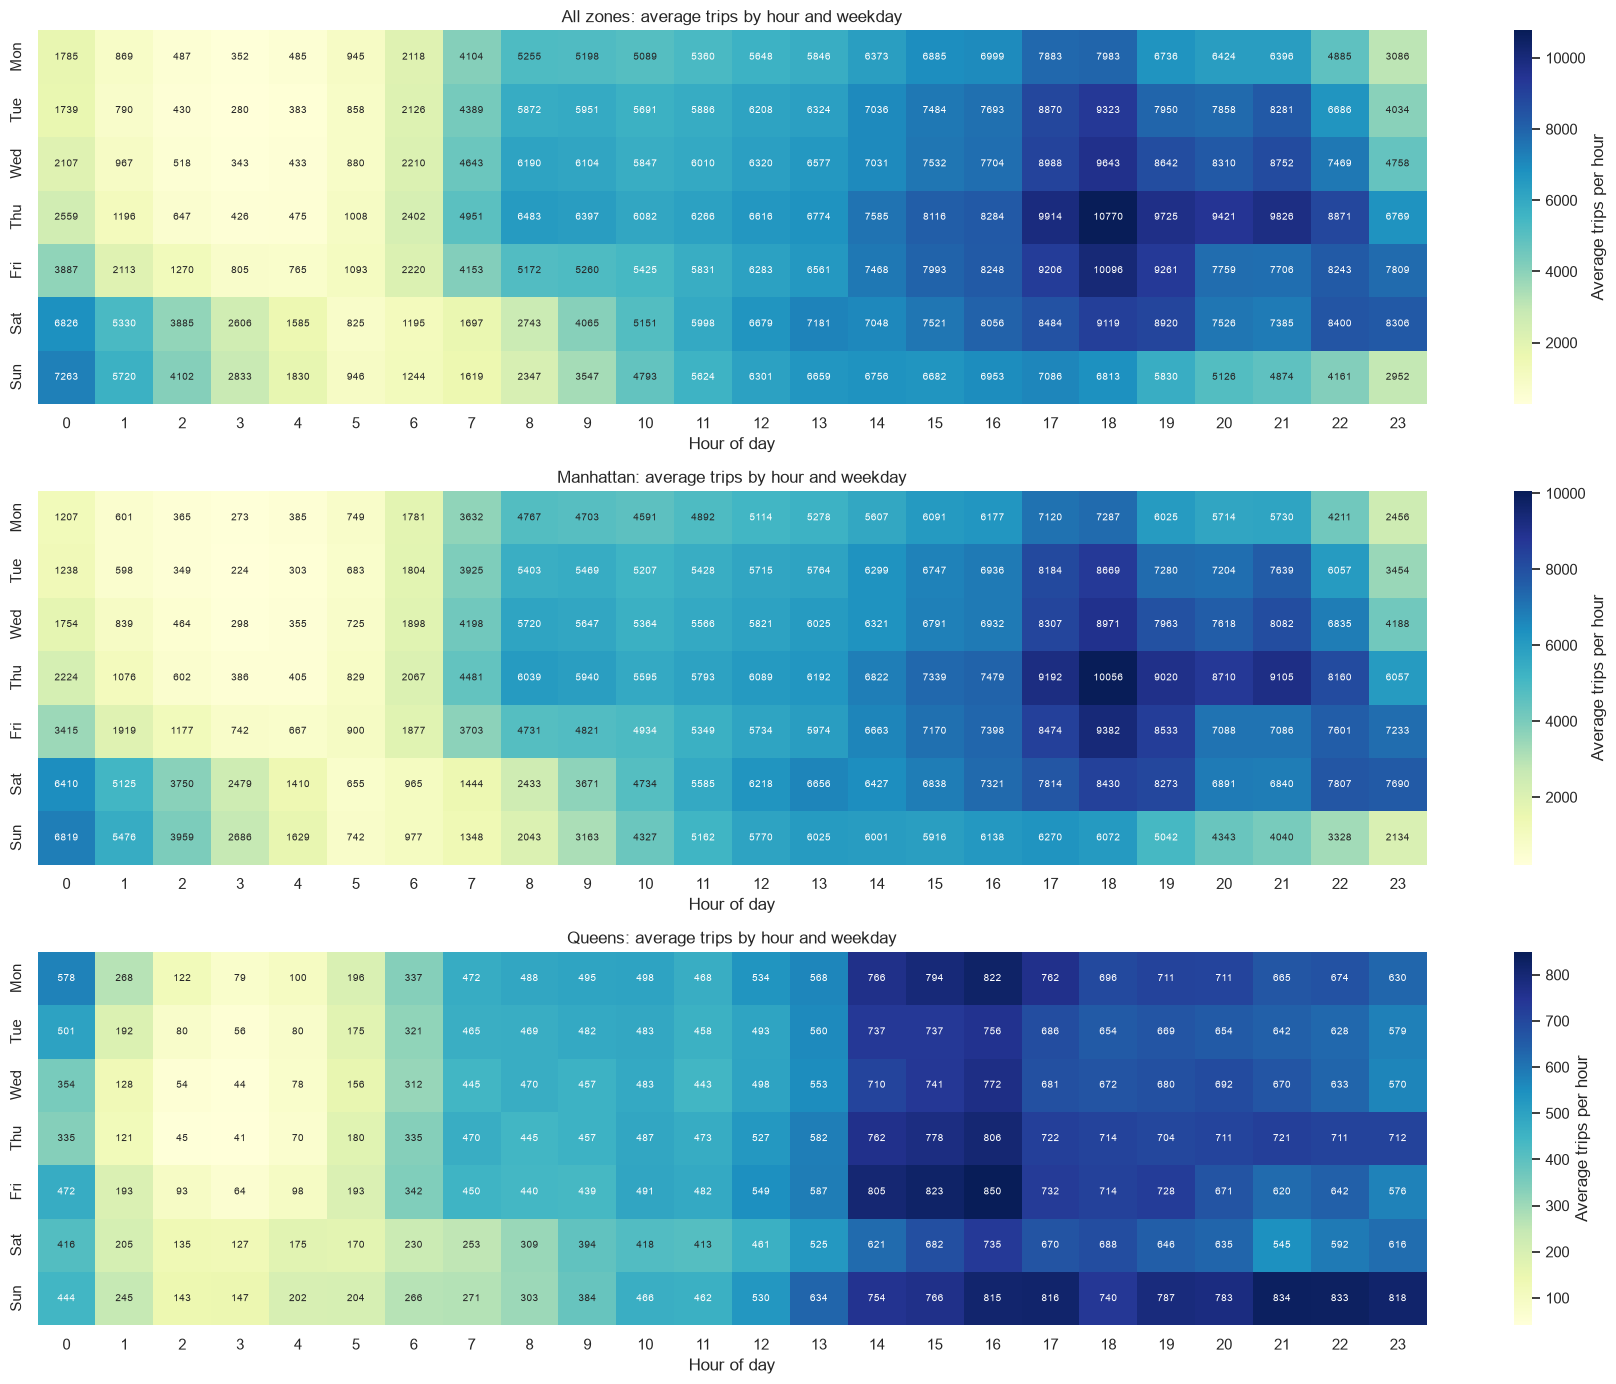

In [35]:
normal_hours = df[(df["is_holiday"] == False) & (df["is_dst_hour"] == False)]


def hour_weekday_table(data):
    # Average total trips for each (weekday, hour) slot
    totals = data.groupby(["pickup_hour", "day_of_week", "hour"])["trip_count"].sum().reset_index()
    table = totals.groupby(["day_of_week", "hour"])["trip_count"].mean().unstack("hour")
    table.index = DAY_NAMES
    return table


week_tables = {
    "All zones": hour_weekday_table(normal_hours),
    "Manhattan": hour_weekday_table(normal_hours[normal_hours["borough"] == "Manhattan"]),
    "Queens": hour_weekday_table(normal_hours[normal_hours["borough"] == "Queens"]),
}

fig, axes = plt.subplots(3, 1, figsize=(18, 14))
for i, (name, table) in enumerate(week_tables.items()):
    sns.heatmap(table, cmap="YlGnBu", annot=True, fmt=".0f", annot_kws={"size": 7},
                ax=axes[i], cbar_kws={"label": "Average trips per hour"})
    axes[i].set_title(name + ": average trips by hour and weekday")
    axes[i].set_xlabel("Hour of day")
    axes[i].set_ylabel("")
save_fig("D7_hour_weekday_heatmap")

In [36]:
table = week_tables["All zones"].stack()
print("Busiest slots:")
print(table.sort_values(ascending=False).head(5).round(0))
print()
print("Quietest slots:")
print(table.sort_values().head(5).round(0))
print()
weekday_night = week_tables["All zones"].loc[["Mon", "Tue", "Wed", "Thu"], [0, 1, 2]].values.mean()
weekend_night = week_tables["All zones"].loc[["Sat", "Sun"], [0, 1, 2]].values.mean()
print("00:00-02:59 average, Mon-Thu:", round(weekday_night), "| Sat-Sun:", round(weekend_night))
print("Queens busiest slot:", week_tables["Queens"].stack().idxmax(), round(week_tables["Queens"].stack().max()))

Busiest slots:
     hour
Thu  18      10770.0
Fri  18      10096.0
Thu  17       9914.0
     21       9826.0
     19       9725.0
dtype: float64

Quietest slots:
     hour
Tue  3       280.0
Wed  3       343.0
Mon  3       352.0
Tue  4       383.0
Thu  3       426.0
dtype: float64

00:00-02:59 average, Mon-Thu: 1175 | Sat-Sun: 5521
Queens busiest slot: ('Fri', np.int64(16)) 850


**Finding:** Busiest slot is Thu 18:00 (10,770/hour). Weekend nights (00-03) are 4.7x busier than weekday nights.

## E5. Anomaly days (vs median of the same weekday within ±4 weeks; robust z > 3)

In [37]:
day_table = daily.reset_index()
day_table.columns = ["date", "trips"]
day_table["weekday"] = day_table["date"].dt.dayofweek
day_table["is_holiday"] = day_table["date"].dt.strftime("%Y-%m-%d").isin(HOLIDAYS.keys())

# Daily weather: citywide average per hour, then summed (rain, snow) or averaged (temperature)
city_weather = df.groupby(["date", "pickup_hour"])[["rain", "snowfall", "apparent_temperature"]].mean().reset_index()
daily_weather = city_weather.groupby("date").agg(
    rain_mm=("rain", "sum"),
    snow_cm=("snowfall", "sum"),
    avg_feels_like_c=("apparent_temperature", "mean"),
).reset_index()
day_table = day_table.merge(daily_weather, on="date")
day_table["is_snow_day"] = day_table["snow_cm"] >= 3

# Normal level = median of the same weekday within 28 days,
# not counting holidays, snowstorm days or the day itself
normal_level = []
for _, row in day_table.iterrows():
    same_weekday = day_table[(day_table["weekday"] == row["weekday"])
                             & (day_table["date"] != row["date"])
                             & (day_table["is_holiday"] == False)
                             & (day_table["is_snow_day"] == False)
                             & ((day_table["date"] - row["date"]).abs() <= pd.Timedelta(days=28))]
    normal_level.append(same_weekday["trips"].median())

day_table["normal"] = normal_level
day_table["deviation"] = day_table["trips"] / day_table["normal"] - 1

# Robust z-score of the deviation
median_dev = day_table["deviation"].median()
mad = (day_table["deviation"] - median_dev).abs().median() * 1.4826
day_table["robust_z"] = (day_table["deviation"] - median_dev) / mad
day_table["is_anomaly"] = day_table["robust_z"].abs() > 3

print("Anomaly days found:", day_table["is_anomaly"].sum(), "of", len(day_table))

Anomaly days found: 18 of 174


In [38]:
# Snow per date, used to spot the day after a snowstorm
snow_by_date = dict(zip(day_table["date"], day_table["snow_cm"]))


# Simple reason for each anomaly day: calendar periods first, then snow
def anomaly_reason(row):
    day = row["date"]
    day_text = day.strftime("%Y-%m-%d")
    snow_today = row["snow_cm"] >= 3
    snow_yesterday = snow_by_date.get(day - pd.Timedelta(days=1), 0) >= 3

    if day_text in HOLIDAYS:
        reason = "Holiday: " + HOLIDAYS[day_text]
    elif pd.Timestamp("2025-12-24") <= day <= pd.Timestamp("2026-01-03"):
        reason = "Christmas - New Year period"
    elif pd.Timestamp("2025-11-28") <= day <= pd.Timestamp("2025-11-30"):
        reason = "Thanksgiving weekend"
    elif pd.Timestamp("2025-12-08") <= day <= pd.Timestamp("2025-12-20") and row["deviation"] > 0:
        reason = "Pre-Christmas busy period"
    elif snow_today:
        return "Snowstorm"
    elif snow_yesterday:
        return "Day after a snowstorm"
    else:
        return "Not explained by holiday or weather"

    if snow_today:
        reason = reason + " (with snow)"
    return reason


anomalies = day_table[day_table["is_anomaly"]].copy()
anomalies["weekday"] = anomalies["date"].dt.day_name().str[:3]
anomalies["reason"] = anomalies.apply(anomaly_reason, axis=1)
anomalies = anomalies.sort_values("deviation")

show_cols = ["date", "weekday", "trips", "normal", "deviation", "rain_mm", "snow_cm", "avg_feels_like_c", "reason"]
anomalies[show_cols].round(2)

,date,weekday,trips,normal,deviation,rain_mm,snow_cm,avg_feels_like_c,reason
168,2026-02-23,Mon,22783,104012.0,-0.78,8.41,14.12,-7.58,Snowstorm
139,2026-01-25,Sun,39961,105663.0,-0.62,13.01,19.13,-15.17,Snowstorm
108,2025-12-25,Thu,60817,144204.5,-0.58,0.00,0.00,-2.21,Holiday: Christmas
80,2025-11-27,Thu,86029,152890.0,-0.44,0.00,0.00,0.06,Holiday: Thanksgiving
110,2025-12-27,Sat,79994,135661.5,-0.41,2.65,4.33,-7.26,Christmas - New Year period (with snow)
81,2025-11-28,Fri,93649,156495.0,-0.40,0.00,0.00,-3.53,Thanksgiving weekend
109,2025-12-26,Fri,78219,129808.5,-0.40,3.21,5.40,-9.27,Christmas - New Year period (with snow)
140,2026-01-26,Mon,63387,104012.0,-0.39,0.00,0.00,-11.43,Day after a snowstorm
116,2026-01-02,Fri,92901,140375.0,-0.34,0.00,0.00,-9.23,Christmas - New Year period
167,2026-02-22,Sun,78195,112866.0,-0.31,6.77,9.02,-3.40,Snowstorm


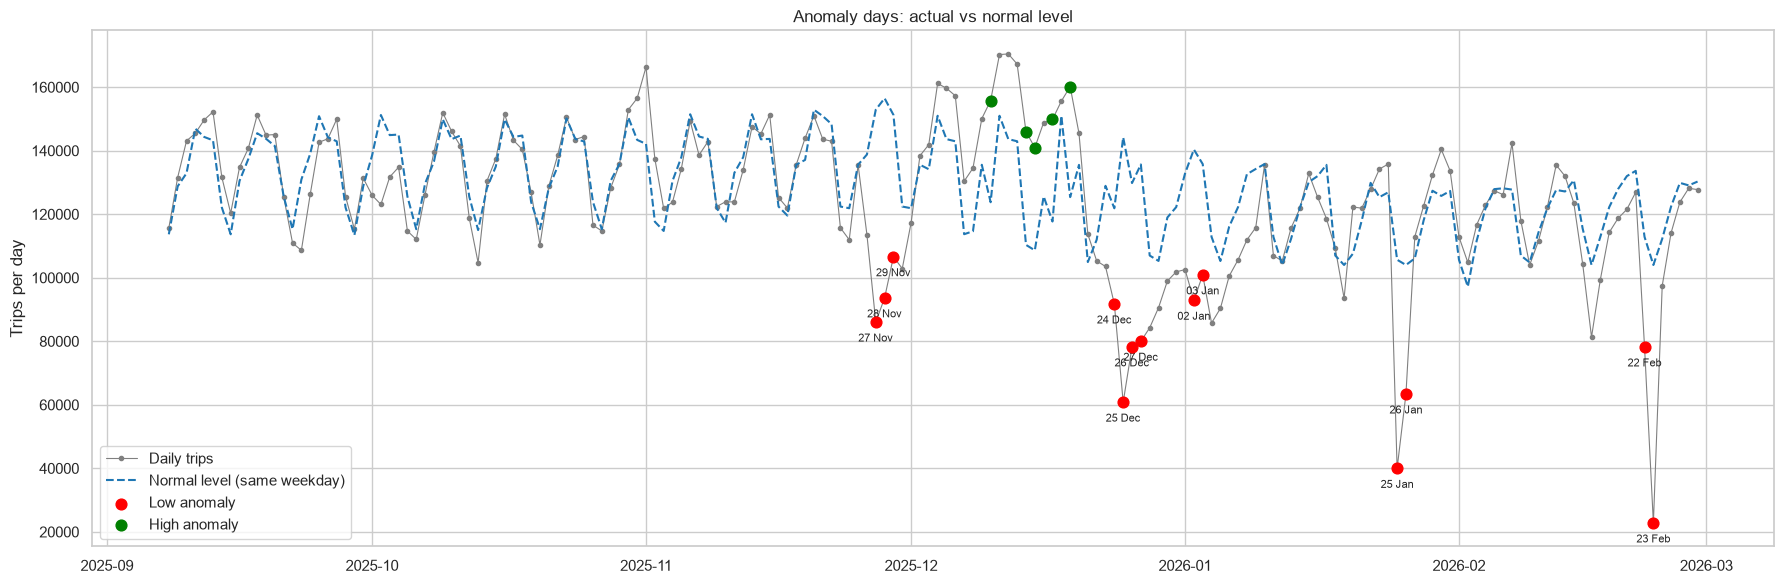

In [39]:
fig, ax = plt.subplots(figsize=(18, 6))
ax.plot(day_table["date"], day_table["trips"], color="gray", marker=".", linewidth=0.8, label="Daily trips")
ax.plot(day_table["date"], day_table["normal"], color="tab:blue", linestyle="--", label="Normal level (same weekday)")

low = anomalies[anomalies["deviation"] < 0]
high = anomalies[anomalies["deviation"] > 0]
ax.scatter(low["date"], low["trips"], color="red", s=60, zorder=5, label="Low anomaly")
ax.scatter(high["date"], high["trips"], color="green", s=60, zorder=5, label="High anomaly")

for _, row in low.iterrows():
    ax.annotate(row["date"].strftime("%d %b"), (row["date"], row["trips"]), fontsize=8,
                xytext=(0, -14), textcoords="offset points", ha="center")

ax.set_ylabel("Trips per day")
ax.set_title("Anomaly days: actual vs normal level")
ax.legend(loc="lower left")
save_fig("E5_anomaly_days")

In [40]:
print(anomalies.groupby("reason")["date"].count().sort_values(ascending=False))

reason
Pre-Christmas busy period                  4
Christmas - New Year period                3
Snowstorm                                  3
Christmas - New Year period (with snow)    2
Thanksgiving weekend                       2
Day after a snowstorm                      1
Holiday: Christmas                         1
Holiday: Thanksgiving                      1
Pre-Christmas busy period (with snow)      1
Name: date, dtype: int64


**Finding:** 18 anomaly days, all explained: holiday periods and snowstorms (low, worst 23 Feb -78%) and the pre-Christmas rush, 10-19 Dec (high, +26-32%).

## E6. Zone spikes (≥ 3x the zone's normal and ≥ 30 extra trips)

In [41]:
zone_normal = df.groupby(["PULocationID", "day_of_week", "hour"])["trip_count"].median().rename("normal").reset_index()
spike_data = df.merge(zone_normal, on=["PULocationID", "day_of_week", "hour"])
spike_data["extra_trips"] = spike_data["trip_count"] - spike_data["normal"]

is_spike = (spike_data["trip_count"] >= 3 * spike_data["normal"].clip(lower=1)) & (spike_data["extra_trips"] >= 30)
spikes = spike_data[is_spike].copy()
print("Spikes found:", len(spikes), "zone-hours in", spikes["PULocationID"].nunique(), "zones")
print()
print("Biggest spikes:")
print(spikes.sort_values("extra_trips", ascending=False)[
    ["pickup_hour", "zone_label", "trip_count", "normal", "extra_trips", "day_type"]].head(15).to_string(index=False))

Spikes found: 738 zone-hours in 73 zones

Biggest spikes:
        pickup_hour                         zone_label  trip_count  normal  extra_trips day_type
2026-01-01 03:00:00                  East Village (79)         558    23.0        535.0  Holiday
2026-01-01 02:00:00                  East Village (79)         547    35.0        512.0  Holiday
2026-01-01 01:00:00                  East Village (79)         450    60.0        390.0  Holiday
2025-11-11 01:00:00            LaGuardia Airport (138)         388    31.0        357.0  Holiday
2025-10-31 02:00:00                  JFK Airport (132)         365    11.0        354.0  Weekday
2025-10-10 00:00:00 Penn Station/Madison Sq West (186)         450   104.0        346.0  Weekday
2025-11-17 22:00:00          Lincoln Square East (142)         483   148.0        335.0  Weekday
2026-01-01 00:00:00                  East Village (79)         428   104.0        324.0  Holiday
2025-12-02 00:00:00            LaGuardia Airport (138)         460   

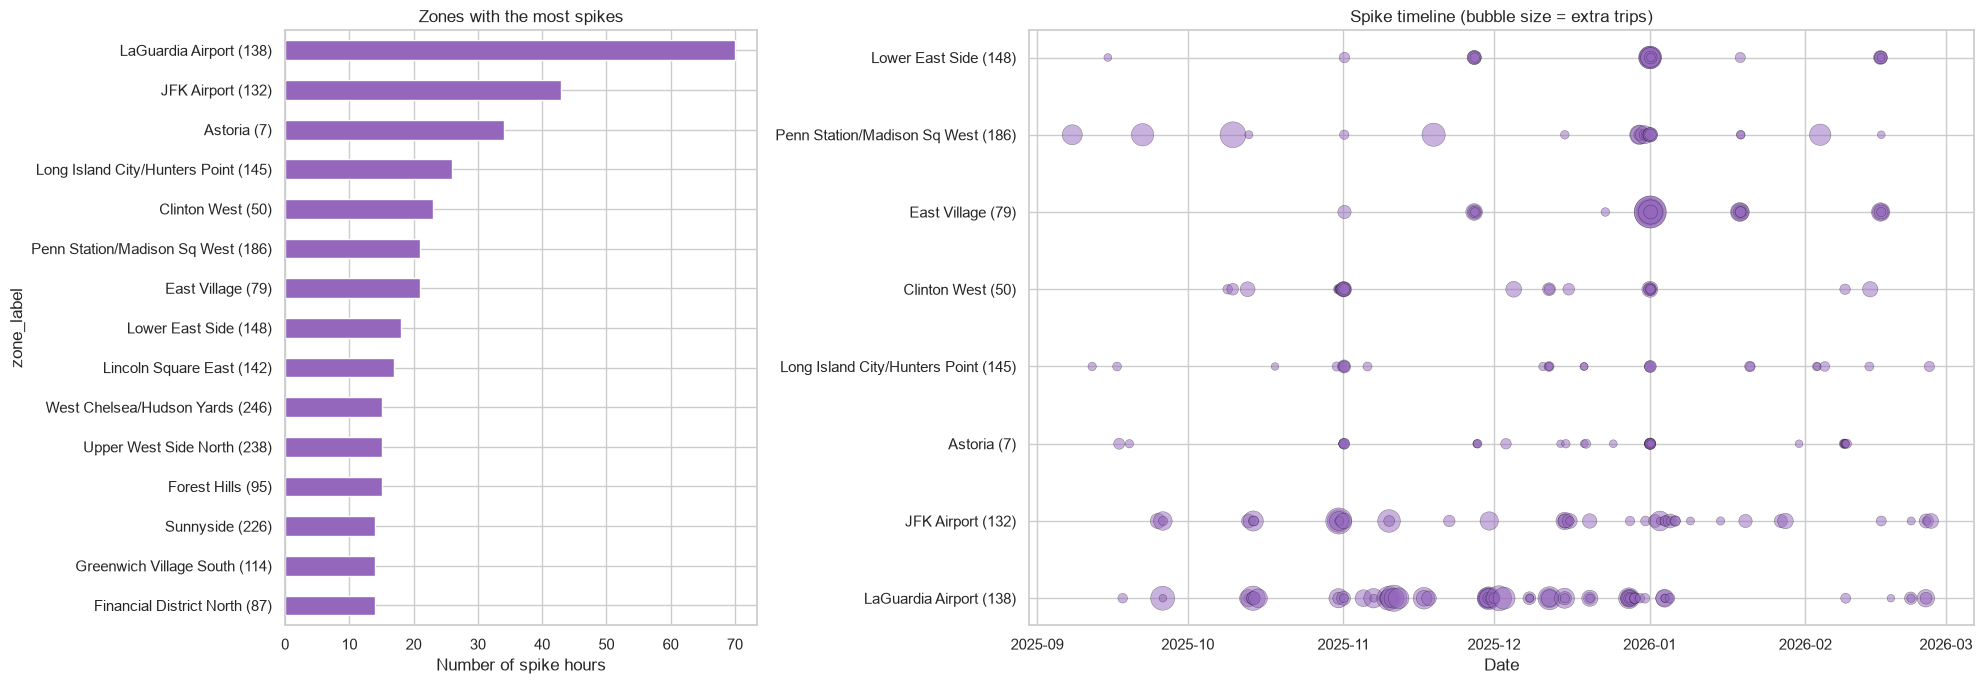

In [42]:
spike_counts = spikes["zone_label"].value_counts().head(15)
top_spike_zones = spike_counts.head(8).index

fig, axes = plt.subplots(1, 2, figsize=(20, 7), gridspec_kw={"width_ratios": [1, 2]})

spike_counts.sort_values().plot(kind="barh", ax=axes[0], color="tab:purple")
axes[0].set_title("Zones with the most spikes")
axes[0].set_xlabel("Number of spike hours")

# Spike timeline for the 8 zones with the most spikes (bubble size = extra trips)
timeline = spikes[spikes["zone_label"].isin(top_spike_zones)]
y_position = {zone: i for i, zone in enumerate(top_spike_zones)}
axes[1].scatter(timeline["pickup_hour"], timeline["zone_label"].map(y_position),
                s=timeline["extra_trips"], alpha=0.5, color="tab:purple", edgecolor="black", linewidth=0.3)
axes[1].set_yticks(range(len(top_spike_zones)))
axes[1].set_yticklabels(top_spike_zones)
axes[1].set_title("Spike timeline (bubble size = extra trips)")
axes[1].set_xlabel("Date")
save_fig("E6_zone_spikes")

In [43]:
# When do spikes happen?
print("Spikes by hour of day (top 6):")
print(spikes["hour"].value_counts().head(6))
print()
print("Share of spikes at the two airports:",
      round(spikes["PULocationID"].isin([132, 138]).mean() * 100, 1), "%")
print()
print("Dates with the most spike hours:")
print(spikes["date"].value_counts().head(6))

Spikes by hour of day (top 6):
hour
1     148
2     137
3     100
0      95
22     67
4      58
Name: count, dtype: int64

Share of spikes at the two airports: 15.3 %

Dates with the most spike hours:
date
2026-01-01    219
2025-11-01     89
2025-11-27     41
2026-02-08     34
2025-12-31     24
2025-10-31     21
Name: count, dtype: int64


**Finding:** 738 spike hours, mostly 00-03. Biggest clusters: New Year's night (219) and Halloween night (89). Airports have 15%; event venues spike repeatedly.

## E7. Daylight saving (DST) hour, 2 Nov 01:00

DST hour trips: 9166
Median of other Sundays at 01:00: 6084
DST hour is 51 % above a normal Sunday 01:00


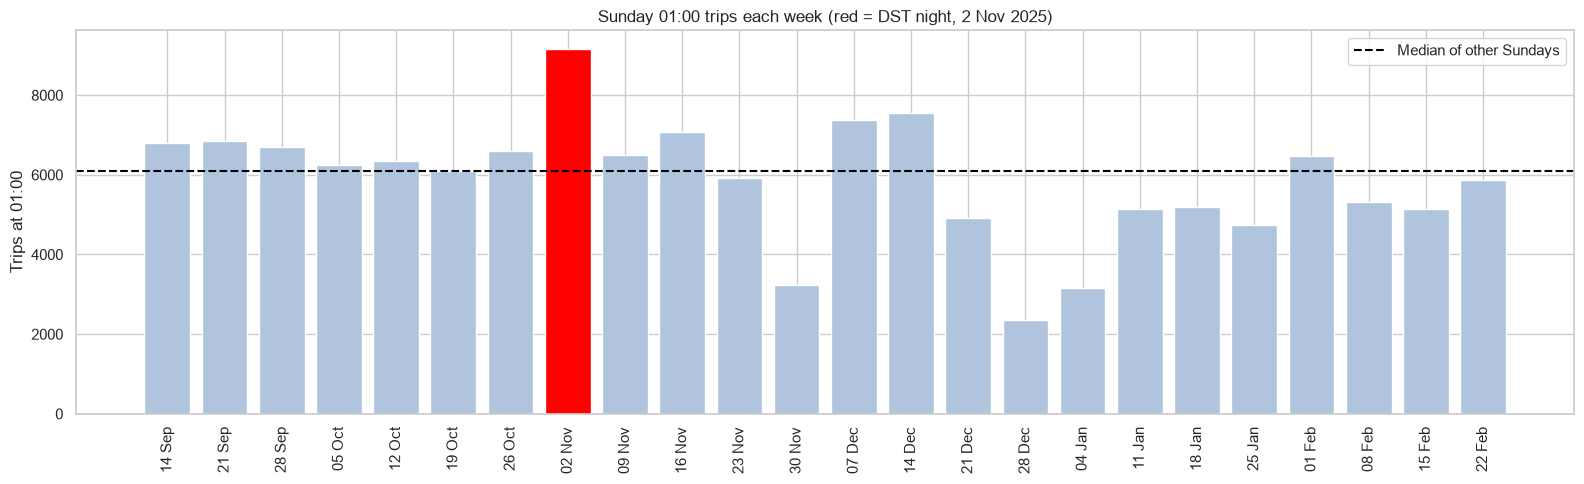

In [44]:
sunday_1am = df[(df["day_of_week"] == 6) & (df["hour"] == 1) & (df["is_holiday"] == False)]
sunday_totals = sunday_1am.groupby("date")["trip_count"].sum()

dst_value = sunday_totals[DST_HOUR.normalize()]
other_sundays = sunday_totals.drop(DST_HOUR.normalize())
print("DST hour trips:", dst_value)
print("Median of other Sundays at 01:00:", round(other_sundays.median()))
print("DST hour is", round((dst_value / other_sundays.median() - 1) * 100), "% above a normal Sunday 01:00")

plt.figure(figsize=(16, 5))
colors = ["red" if d == DST_HOUR.normalize() else "lightsteelblue" for d in sunday_totals.index]
plt.bar([d.strftime("%d %b") for d in sunday_totals.index], sunday_totals.values, color=colors)
plt.axhline(other_sundays.median(), color="black", linestyle="--", label="Median of other Sundays")
plt.xticks(rotation=90)
plt.ylabel("Trips at 01:00")
plt.title("Sunday 01:00 trips each week (red = DST night, 2 Nov 2025)")
plt.legend()
save_fig("E7_dst_hour")

In [45]:
# How much each zone is inflated at the DST hour
zone_dst = df[df["pickup_hour"] == DST_HOUR][["PULocationID", "zone_label", "trip_count"]]
zone_sunday_median = sunday_1am[sunday_1am["date"] != DST_HOUR.normalize()].groupby("PULocationID")["trip_count"].median().rename("normal")
zone_dst = zone_dst.merge(zone_sunday_median, on="PULocationID")
zone_dst = zone_dst[zone_dst["normal"] >= 10]          # only zones with real night demand
zone_dst["ratio"] = zone_dst["trip_count"] / zone_dst["normal"]
print("Zones checked:", len(zone_dst))
print("Median ratio (DST hour / normal):", round(zone_dst["ratio"].median(), 2))
print(zone_dst.sort_values("trip_count", ascending=False).head(5)[["zone_label", "trip_count", "normal", "ratio"]].round(2).to_string(index=False))

Zones checked: 55
Median ratio (DST hour / normal): 1.71
                   zone_label  trip_count  normal  ratio
            East Village (79)        1122   814.0   1.38
        Lower East Side (148)         673   442.0   1.52
           West Village (249)         607   493.0   1.23
Greenwich Village South (114)         576   427.0   1.35
               Gramercy (107)         334   151.0   2.21


In [46]:
# Lag features that copy the DST value into later rows
lag_rows = pd.DataFrame({
    "row": ["2025-11-03 01:00 (lag 24h)", "2025-11-09 01:00 (lag 168h)"],
    "lag_value_citywide": [
        df[df["pickup_hour"] == pd.Timestamp("2025-11-03 01:00")]["trip_count_lag_24h"].sum(),
        df[df["pickup_hour"] == pd.Timestamp("2025-11-09 01:00")]["trip_count_lag_168h"].sum(),
    ],
})
lag_rows["dst_hour_value"] = dst_value
lag_rows["normal_sunday_1am"] = round(other_sundays.median())
lag_rows

,row,lag_value_citywide,dst_hour_value,normal_sunday_1am
0,2025-11-03 01:00 (lag 24h),9166,9166,6084
1,2025-11-09 01:00 (lag 168h),9166,9166,6084


**Finding:** The DST hour is 51% above a normal Sunday 01:00, and the value is copied into lag_24h (3 Nov) and lag_168h (9 Nov). Flag or fix these rows before modelling.

## B6. The 50 busiest zone-hours

In [47]:
top50 = df.sort_values("trip_count", ascending=False).head(50).copy()
top50["weekday"] = top50["pickup_hour"].dt.day_name().str[:3]
print(top50[["pickup_hour", "weekday", "zone_label", "trip_count", "day_type", "apparent_temperature", "rain"]].head(15).to_string(index=False))

        pickup_hour weekday        zone_label  trip_count day_type  apparent_temperature  rain
2025-11-02 01:00:00     Sun East Village (79)        1122  Weekend                   3.6   0.0
2025-09-14 01:00:00     Sun East Village (79)         984  Weekend                  20.7   0.0
2025-12-07 01:00:00     Sun East Village (79)         950  Weekend                  -4.5   0.0
2025-09-21 01:00:00     Sun East Village (79)         910  Weekend                  14.6   0.0
2025-10-12 01:00:00     Sun East Village (79)         909  Weekend                  12.4   0.0
2026-02-01 01:00:00     Sun East Village (79)         905  Weekend                 -17.0   0.0
2025-09-28 00:00:00     Sun East Village (79)         894  Weekend                  22.5   0.7
2025-10-26 01:00:00     Sun East Village (79)         894  Weekend                   7.9   0.0
2025-11-15 00:00:00     Sat East Village (79)         874  Weekend                   2.5   0.0
2025-11-16 01:00:00     Sun East Village (79)     

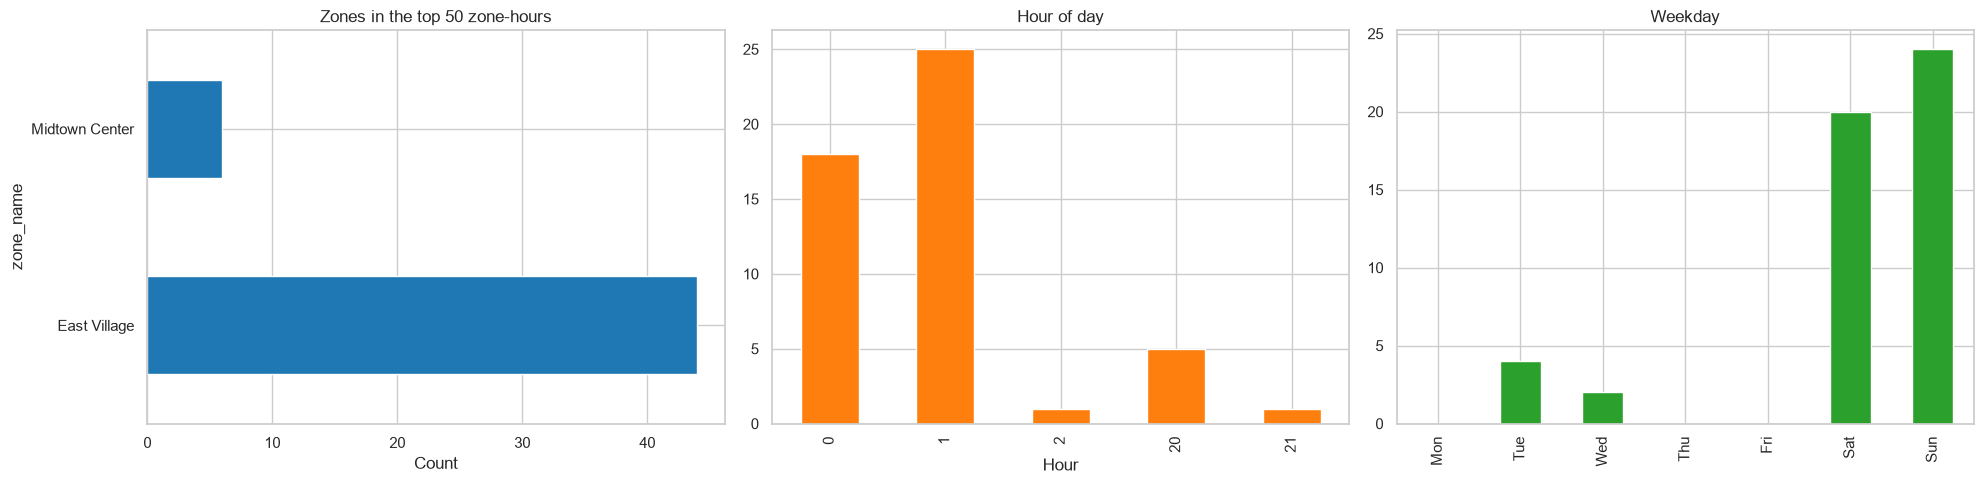

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

top50["zone_name"].value_counts().plot(kind="barh", ax=axes[0], color="tab:blue")
axes[0].set_title("Zones in the top 50 zone-hours")
axes[0].set_xlabel("Count")

top50["hour"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="tab:orange")
axes[1].set_title("Hour of day")
axes[1].set_xlabel("Hour")

top50["weekday"].value_counts().reindex(DAY_NAMES).fillna(0).plot(kind="bar", ax=axes[2], color="tab:green")
axes[2].set_title("Weekday")
axes[2].set_xlabel("")
save_fig("B6_top50_zone_hours")

**Finding:** Real demand, not errors: 44 are East Village weekend nights at 00-01, 6 are Midtown Center weekday evenings.